# Classical AI: Reasoning and Planning

> **Who is this for:** a beginner who has finished [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) and knows high-school maths, or a university student revising reasoning and automated planning for an exam or interview.
>
> **What you will learn**
> - The main **types of reasoning** with definitions, examples and a small code demo each: **deductive**, **inductive**, **abductive**, **analogical**, **common-sense**, and **monotonic vs non-monotonic** (default) reasoning
> - **Classical planning**: the STRIPS/PDDL representation (preconditions, add and delete lists), with real PDDL text parsed by our own Python parser
> - **Forward (progression)** planning with BFS and with A* using **ignore-preconditions** and **ignore-delete-lists** heuristics; **backward (regression)** planning
> - Solving the **blocks world** (3 to 5 blocks, including the Sussman anomaly) and the **air cargo** logistics problem, with every plan checked by simulation
> - **Partial-order planning**, **GraphPlan** and **hierarchical task networks (HTN)**, briefly
> - How planning differs from plain search and from reinforcement learning, and how it connects to **plan-and-execute LLM agents**
>
> **Prerequisites:** [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb). Recommended: [`07_knowledge_representation_and_logic.ipynb`](07_knowledge_representation_and_logic.ipynb) (logic, forward chaining), [`02_uninformed_search.ipynb`](02_uninformed_search.ipynb) (uninformed search: BFS), [`03_informed_search.ipynb`](03_informed_search.ipynb) (informed search: A* and heuristics).
>
> **Time needed:** about 3 hours (reading, running, and the practice problems).
>
> **Runs on:** CPU, no API key, no internet. Libraries: Python standard library, pandas, matplotlib, networkx.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Russell & Norvig, *Artificial Intelligence: A Modern Approach* (AIMA, 4th ed.), Ch. 10 (knowledge representation, defaults) and Ch. 11 (automated planning).

## Explained simply

**Reasoning** means using what you know to reach a new conclusion, and there is more than one way to do it. Sometimes the conclusion is certain (deduction), sometimes it is a smart generalisation (induction), and sometimes it is the most likely explanation (abduction). **Planning** means working out, *before* you act, a sequence of steps that gets you from where you are to where you want to be. A planner needs to know what each action requires and what it changes, and then it searches for a sequence that works. This is how warehouse robots, delivery schedulers and many game characters decide what to do next.

- **Everyday example 1 (reasoning):** a doctor sees a fever and a rash and thinks "probably measles". That is not a proof, it is the *best explanation* of the symptoms, and a new test result can change her mind.
- **Everyday example 2 (planning):** making breakfast. You cannot butter the toast before toasting the bread, and you must put the kettle on before pouring tea. Getting the order right is planning.
- **Tiny example you can follow:** three blocks on a table: C is on top of A, and B is alone. You want a tower with A on B and B on C. A planner finds 6 moves: lift C off A, put C on the table, pick up B, put B on C, pick up A, put A on B. If you try to put A on B first, you later have to undo it, so the order of the moves really matters.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Deduction / induction / abduction | certain conclusion / general rule from examples / best guess at a cause | maths proofs / machine learning / medical and car diagnosis |
| Planning | finding a sequence of actions that reaches a goal | delivery and logistics software, robots, game characters |
| Replanning | fixing the plan when the world surprises you | sat-nav recalculating a route, LLM agents retrying a failed step |

## Contents

1. What "reasoning" means, and a map of the types
2. Deductive reasoning
3. Inductive reasoning (learning a rule from examples)
4. Abductive reasoning (diagnosis: inference to the best explanation)
5. Analogical reasoning (structure mapping)
6. Common-sense reasoning
7. Monotonic vs non-monotonic reasoning (defaults and exceptions)
8. Classical planning: STRIPS and PDDL
9. Forward (progression) planning: BFS and A* with relaxation heuristics
10. Backward (regression) planning
11. Solving the blocks world and the air cargo problem
12. The Sussman anomaly and partial-order planning
13. GraphPlan, briefly
14. Hierarchical task networks, briefly
15. Planning vs search vs reinforcement learning
16. Plan, execute, monitor, replan: the link to LLM agents
17. How this connects to modern AI
18. Recap, practice problems, further reading

In [1]:
# Setup: every library used in this notebook (CPU only, no network).
import heapq                      # priority queue for A*
import itertools                  # products / permutations for grounding and enumeration
import math                       # logs for probabilities
import random                     # seeded randomness
import time                       # timing comparisons
from collections import deque, namedtuple

import matplotlib.pyplot as plt   # plots
import networkx as nx             # graph drawings
import pandas as pd               # tables for traces

random.seed(0)
pd.set_option("display.max_colwidth", 140)
print("Setup complete. networkx", nx.__version__, "| pandas", pd.__version__)

Setup complete. networkx 3.7 | pandas 2.3.3


## 1. What is reasoning?

> **In plain English:** reasoning is reaching conclusions; some kinds give certainty, others give good guesses.

**Reasoning** is the process of drawing **conclusions** from **premises** (what you already know or observe). The previous notebook studied one kind, logical deduction, in depth. Humans and AI systems use several other kinds, and they differ in one crucial way: **is the conclusion guaranteed to be true when the premises are?**

The three classic forms were named by the philosopher Charles S. Peirce. Using the rule "beans from this bag are white":

| Type | Given | Conclude | Guaranteed? | Example |
|---|---|---|---|---|
| **Deduction** | rule + case | result | **yes** (truth-preserving) | All beans from this bag are white; these beans are from this bag ⇒ these beans are white |
| **Induction** | case + result (many times) | rule | no (could be wrong next time) | These beans are from this bag; they are all white ⇒ all beans from this bag are white |
| **Abduction** | rule + result | case | no (a best guess) | All beans from this bag are white; these beans are white ⇒ these beans (probably) came from this bag |

Further types used in AI:

| Type | Idea | Typical AI technique |
|---|---|---|
| **Analogical** | transfer knowledge from a familiar situation to a similar new one | case-based reasoning, structure mapping |
| **Common-sense** | everyday background knowledge people never state | Cyc, ConceptNet, large language models |
| **Monotonic** | adding knowledge never removes conclusions | classical logic |
| **Non-monotonic** | new knowledge can **withdraw** earlier conclusions | default logic, negation as failure, belief revision |

## 2. Deductive reasoning

> **In plain English:** deduction gives conclusions that must be true if the starting facts are true.

**Intuition.** A detective who says "the thief had a key; only the butler had a key; so the butler is the thief" is deducing. If the premises are true, the conclusion **must** be true.

**Definition.** **Deductive reasoning** derives conclusions that are **logically entailed** by the premises. It is **sound** (truth-preserving) but **adds no information** that was not already implicit in the premises. Classic rule patterns:

| Rule | Form | Example |
|---|---|---|
| **Modus ponens** | P ⇒ Q, P ⊢ Q | If it rains the grass is wet; it rains ⊢ the grass is wet |
| **Modus tollens** | P ⇒ Q, ¬Q ⊢ ¬P | If it rains the grass is wet; the grass is dry ⊢ it did not rain |
| **Hypothetical syllogism** | P ⇒ Q, Q ⇒ R ⊢ P ⇒ R | Humans are mammals; mammals are animals ⊢ humans are animals |
| **Universal instantiation** | ∀x P(x) ⊢ P(Socrates) | All humans are mortal ⊢ Socrates is mortal |

Below: a tiny rule engine that applies "every X is a Y" rules (modus ponens with universal instantiation) and also uses **modus tollens** in the backward direction.

In [2]:
rules_is_a = [("human", "mammal"), ("mammal", "animal"), ("animal", "mortal"), ("robot", "machine")]   # every X is a Y

def deduce(facts, rules):
    """Apply 'every X is a Y' rules until nothing new follows (forward chaining)."""
    facts, trace = set(facts), []
    changed = True
    while changed:
        changed = False
        for (cls, who) in sorted(facts):
            for x, y in rules:
                if cls == x and (y, who) not in facts:          # modus ponens: X(who) and X => Y give Y(who)
                    facts.add((y, who)); changed = True
                    article = "an" if y[0] in "aeiou" else "a"
                    trace.append(f"{x}({who}) and 'every {x} is {article} {y}'  ⊢  {y}({who})")
    return facts, trace

def modus_tollens(not_fact, rules):
    """From ¬Y(who) and X => Y, conclude ¬X(who), repeatedly."""
    negatives, frontier = {not_fact}, [not_fact]
    while frontier:
        y, who = frontier.pop()
        for x, yy in rules:
            if yy == y and (x, who) not in negatives:
                negatives.add((x, who)); frontier.append((x, who))
    return negatives

facts, trace = deduce({("human", "Socrates"), ("robot", "R2")}, rules_is_a)
print("\n".join(trace))
print("\nModus tollens from ¬mortal(Zeus):", sorted(f"¬{c}({w})" for c, w in modus_tollens(("mortal", "Zeus"), rules_is_a)))
assert ("mortal", "Socrates") in facts and ("mortal", "R2") not in facts
assert ("human", "Zeus") in modus_tollens(("mortal", "Zeus"), rules_is_a)

human(Socrates) and 'every human is a mammal'  ⊢  mammal(Socrates)
robot(R2) and 'every robot is a machine'  ⊢  machine(R2)
mammal(Socrates) and 'every mammal is an animal'  ⊢  animal(Socrates)
animal(Socrates) and 'every animal is a mortal'  ⊢  mortal(Socrates)

Modus tollens from ¬mortal(Zeus): ['¬animal(Zeus)', '¬human(Zeus)', '¬mammal(Zeus)', '¬mortal(Zeus)']


**What just happened?** Starting from "Socrates is human", three applications of modus ponens chained to "Socrates is mortal". Nothing about mortality was concluded for the robot because no rule links machines to mortality. Modus tollens ran the rules backwards for negative facts: if Zeus is not mortal, he is not an animal, not a mammal and not a human.

> ⚠️ **Common mistake:** two *invalid* patterns look like deduction. **Affirming the consequent** (P ⇒ Q, Q ⊢ P: "the grass is wet, so it rained") and **denying the antecedent** (P ⇒ Q, ¬P ⊢ ¬Q: "it did not rain, so the grass is dry"). The first is actually **abduction** (Section 4): a plausible guess, not a proof.

## 3. Inductive reasoning

> **In plain English:** induction spots a pattern in examples and guesses a general rule, which might later turn out wrong.

**Intuition.** You have seen 1,000 swans and every one was white, so you conclude "all swans are white". Useful, but a single black swan (found in Australia) proves it wrong.

**Definition.** **Inductive reasoning** generalises from specific examples to a general rule. The conclusion goes **beyond** the premises, so it is **not truth-preserving**: it can be overturned by new data. All of **machine learning** is induction: a model generalises from training examples to unseen cases. What makes induction possible is an **inductive bias**, the assumptions a learner uses to pick one generalisation among many (for example "the rule is a conjunction of attribute values", or "simpler is better", Occam's razor).

**A tiny inductive learner: Find-S** (Mitchell, *Machine Learning*, 1997, Ch. 2). Hypotheses are conjunctions of attribute constraints, where `?` means "any value". Find-S starts from the most specific hypothesis (matches nothing) and minimally generalises it to cover each **positive** example; it ignores negatives.

Data: on which days does Aldo enjoy his water sport?

| Sky | AirTemp | Humidity | Wind | Water | Forecast | EnjoySport |
|---|---|---|---|---|---|---|
| Sunny | Warm | Normal | Strong | Warm | Same | Yes |
| Sunny | Warm | High | Strong | Warm | Same | Yes |
| Rainy | Cold | High | Strong | Warm | Change | No |
| Sunny | Warm | High | Strong | Cool | Change | Yes |

Hand trace: start with ∅. Example 1 → ⟨Sunny, Warm, Normal, Strong, Warm, Same⟩. Example 2 differs in Humidity → ⟨Sunny, Warm, **?**, Strong, Warm, Same⟩. Example 3 is negative: ignored. Example 4 differs in Water and Forecast → ⟨Sunny, Warm, ?, Strong, **?**, **?**⟩.

In [3]:
attributes = ["Sky", "AirTemp", "Humidity", "Wind", "Water", "Forecast"]
examples = [
    (("Sunny", "Warm", "Normal", "Strong", "Warm", "Same"), True),
    (("Sunny", "Warm", "High", "Strong", "Warm", "Same"), True),
    (("Rainy", "Cold", "High", "Strong", "Warm", "Change"), False),
    (("Sunny", "Warm", "High", "Strong", "Cool", "Change"), True),
]

def find_s(examples):
    h = None                                            # most specific hypothesis: covers nothing
    history = []
    for x, label in examples:
        if label:                                       # only positive examples change h
            if h is None:
                h = list(x)                             # first positive: copy it exactly
            else:
                h = [hv if hv == xv else "?" for hv, xv in zip(h, x)]   # generalise mismatches to '?'
        history.append(("∅" if h is None else "⟨" + ", ".join(h) + "⟩", "positive" if label else "negative (ignored)"))
    return h, history

def covers(h, x):
    return all(hv == "?" or hv == xv for hv, xv in zip(h, x))

h, history = find_s(examples)
display(pd.DataFrame(history, columns=["hypothesis after example", "example type"], index=[1, 2, 3, 4]))
print("Learned rule: EnjoySport if " + " AND ".join(f"{a} = {v}" for a, v in zip(attributes, h) if v != "?"))
assert h == ["Sunny", "Warm", "?", "Strong", "?", "?"]
assert all(covers(h, x) == y for x, y in examples)          # consistent with every training example

new_days = [("Sunny", "Warm", "Low", "Strong", "Cool", "Same"), ("Sunny", "Cold", "High", "Strong", "Warm", "Same")]
for d in new_days:
    print(f"Prediction for unseen day {d}: {'Yes' if covers(h, d) else 'No'}")

,hypothesis after example,example type
1,"⟨Sunny, Warm, Normal, Strong, Warm, Same⟩",positive
2,"⟨Sunny, Warm, ?, Strong, Warm, Same⟩",positive
3,"⟨Sunny, Warm, ?, Strong, Warm, Same⟩",negative (ignored)
4,"⟨Sunny, Warm, ?, Strong, ?, ?⟩",positive


Learned rule: EnjoySport if Sky = Sunny AND AirTemp = Warm AND Wind = Strong
Prediction for unseen day ('Sunny', 'Warm', 'Low', 'Strong', 'Cool', 'Same'): Yes
Prediction for unseen day ('Sunny', 'Cold', 'High', 'Strong', 'Warm', 'Same'): No


**What just happened?** From three positive days Find-S *induced* the rule "Sky = Sunny AND AirTemp = Warm AND Wind = Strong", and used it to predict days it had never seen. Note the leap: nothing in the data *proves* that Humidity never matters. If tomorrow is Sunny, Warm, Strong-wind and Aldo stays home, the rule is falsified, exactly like the black swan.

**Complexity.** Find-S makes one pass: O(n · d) for n examples and d attributes. Its weaknesses (it cannot handle noise, and ignores negatives) motivated the *candidate elimination* algorithm and, later, decision trees and statistical learning.

> 🎓 **Exam / interview tip:** "Is induction valid?" No: inductive conclusions are **defeasible** and only probable. This is **Hume's problem of induction**. In ML terms it is why we need held-out test data: training accuracy proves nothing about the next example.

## 4. Abductive reasoning (inference to the best explanation)

> **In plain English:** abduction picks the most likely explanation for what you observe, like a mechanic guessing why a car won't start.

**Intuition.** Your car will not start and the headlights are dim. You think: "probably the battery is dead". You did not *prove* it (a blown fuse could also explain it), but it is the **best explanation** of what you see. Doctors, mechanics and detectives reason this way.

**Definition.** **Abduction**: given background knowledge "H would cause E" and an observation E, infer H as a hypothesis that **explains** E. Formally, find H such that KB ∧ H ⊨ E and KB ∧ H is consistent. Abduction is **not sound** (it is "affirming the consequent"), so we need a way to choose among explanations:
- **Parsimony / minimality:** prefer explanations with fewer assumptions (Occam's razor), or set-minimal ones (no proper subset also explains E).
- **Probability:** prefer the hypothesis with the highest posterior P(H | E) ∝ P(E | H) · P(H) (Bayes' rule). This is how diagnosis systems rank causes.

**Diagnosis example.** Possible faults (with prior probabilities) and the symptoms each tends to cause (with the probability it causes them):

| Fault | Prior | Symptoms it causes |
|---|---|---|
| dead battery | 0.05 | engine does not crank (0.95), dim lights (0.90), radio dead (0.70) |
| faulty starter motor | 0.02 | engine does not crank (0.90) |
| blown main fuse | 0.01 | engine does not crank (0.90), radio dead (0.95) |
| empty fuel tank | 0.03 | cranks but will not start (0.95) |

We combine several faults with a **noisy-OR** model: a symptom appears unless *every* present cause independently fails to produce it (plus a small "leak" probability that it appears for no modelled reason).

In [4]:
faults = {   # fault: (prior probability, {symptom: P(fault causes symptom)})
    "dead_battery":   (0.05, {"no_crank": 0.95, "dim_lights": 0.90, "radio_dead": 0.70}),
    "faulty_starter": (0.02, {"no_crank": 0.90}),
    "blown_fuse":     (0.01, {"no_crank": 0.90, "radio_dead": 0.95}),
    "empty_tank":     (0.03, {"cranks_no_start": 0.95}),
}
symptoms = ["no_crank", "dim_lights", "radio_dead", "cranks_no_start"]
LEAK = 0.01                                               # a symptom can appear with no modelled cause

def p_symptom(symptom, present_faults):
    """Noisy-OR: P(symptom | the set of present faults)."""
    p_absent = 1 - LEAK
    for f in present_faults:
        p_absent *= 1 - faults[f][1].get(symptom, 0.0)    # each cause independently fails to cause it
    return 1 - p_absent

def rank_explanations(observed):
    """Score every subset of faults by P(H) * P(observations | H), then normalise to P(H | obs)."""
    rows = []
    for k in range(len(faults) + 1):
        for H in itertools.combinations(faults, k):
            prior = 1.0
            for f, (p, _) in faults.items():
                prior *= p if f in H else 1 - p          # faults occur independently
            likelihood = 1.0
            for s, present in observed.items():
                ps = p_symptom(s, H)
                likelihood *= ps if present else 1 - ps
            rows.append({"hypothesis": " + ".join(H) if H else "(no fault)", "size": k,
                         "explains all symptoms?": all(any(s in faults[f][1] for f in H) for s, v in observed.items() if v),
                         "score": prior * likelihood})
    df = pd.DataFrame(rows)
    df["posterior"] = df["score"] / df["score"].sum()     # Bayes: normalise over all hypotheses
    return df.sort_values("posterior", ascending=False).reset_index(drop=True)

obs1 = {"no_crank": True, "dim_lights": True}
ranked1 = rank_explanations(obs1)
print("Observed: engine does not crank, lights are dim")
display(ranked1.head(5).round(4))
assert abs(ranked1["posterior"].sum() - 1) < 1e-9
assert ranked1.loc[0, "hypothesis"] == "dead_battery"

Observed: engine does not crank, lights are dim


,hypothesis,size,explains all symptoms?,score,posterior
0,dead_battery,1,True,0.0403,0.9322
1,dead_battery + empty_tank,2,True,0.0012,0.0288
2,dead_battery + faulty_starter,2,True,0.0009,0.0199
3,dead_battery + blown_fuse,2,True,0.0004,0.0099
4,faulty_starter,1,False,0.0002,0.0038


In [5]:
# New evidence: the radio WORKS and the lights are NOT dim. Abduction is defeasible: the best explanation changes.
obs2 = {"no_crank": True, "dim_lights": False, "radio_dead": False}
ranked2 = rank_explanations(obs2)
print("Observed: engine does not crank, lights fine, radio works")
display(ranked2.head(4).round(4))
assert ranked2.loc[0, "hypothesis"] == "faulty_starter"

# Parsimony view: the set-minimal explanations of {no_crank, dim_lights}, ignoring probabilities.
def minimal_explanations(needed):
    covers_all = [set(H) for k in range(1, len(faults) + 1) for H in itertools.combinations(faults, k)
                  if all(any(s in faults[f][1] for f in H) for s in needed)]
    return [sorted(H) for H in covers_all if not any(other < H for other in covers_all)]
print("Set-minimal explanations of {no_crank, dim_lights}:", minimal_explanations(["no_crank", "dim_lights"]))

Observed: engine does not crank, lights fine, radio works

,hypothesis,size,explains all symptoms?,score,posterior
0,faulty_starter,1,True,0.0161,0.5870
1,(no fault),0,False,0.0088,0.3192
2,dead_battery,1,True,0.0013,0.0479
3,faulty_starter + empty_tank,2,True,0.0005,0.0182


Set-minimal explanations of {no_crank, dim_lights}: [['dead_battery']]


**What just happened?**
- With "no crank + dim lights", the dead battery was the best explanation by far: it is the only single fault that explains *both* symptoms, and it is also the most common fault.
- With "no crank, but lights fine and radio working", the battery became unlikely (a dead battery would very probably dim the lights and kill the radio), and the **faulty starter** took first place. "(no fault)" came second: our model allows a 1% "leak" chance of a symptom with no modelled cause, a reminder that a diagnosis model can be incomplete. The earlier conclusion was **withdrawn** in the light of new evidence, which is why abduction is called *defeasible*.
- The pure-logic view (set-minimal covers) only told us that `dead_battery` is the one minimal single-fault explanation; the probabilistic view ranks *all* hypotheses.

**Complexity.** We enumerated all 2ᵏ subsets of k faults, which is fine for 4 faults but exponential in general; finding a minimum-size explanation is a set-cover problem (NP-hard). Real diagnosis uses **Bayesian networks** (next notebook) and approximate inference.

## 5. Analogical reasoning

> **In plain English:** analogy says 'this new thing works like that familiar thing', and borrows what we know about the familiar one.

**Intuition.** Rutherford's atom was explained to generations of students as "a tiny solar system": the nucleus is like the sun, electrons are like planets. Knowing how planets behave, you guess how electrons behave.

**Definition.** **Analogical reasoning** maps a familiar **base (source)** domain onto a new **target** domain and **transfers** knowledge that holds in the base. Gentner's **structure-mapping theory** (1983) says good analogies map **relations**, not surface attributes (the sun is hot and yellow; the nucleus is neither), and prefer **systematic** mappings: relations that belong to a connected causal structure are transferred, isolated facts are not (**systematicity principle**).

In AI this appears as **case-based reasoning** (solve a new problem by adapting the solution of the most similar old case: legal reasoning, help desks) and in the structure-mapping engine (SME).

Our demo: find the object mapping that preserves the most relations, then transfer the base relations that are part of the causal story.

In [6]:
base = {   # relation -> (args, part of the causal structure?)
    "attracts":        (("sun", "planet"), True),
    "more_massive":    (("sun", "planet"), True),
    "revolves_around": (("planet", "sun"), True),    # caused by attraction + mass difference
    "hotter_than":     (("sun", "planet"), False),   # an isolated fact, not part of the causal story
}
base_cause = "attracts ∧ more_massive  CAUSE  revolves_around"
target = {"attracts": ("nucleus", "electron"), "more_massive": ("nucleus", "electron")}
base_objects, target_objects = ["sun", "planet"], ["nucleus", "electron"]

def score(mapping):
    """Number of target relations whose arguments are preserved by the object mapping."""
    return sum(1 for r, args in target.items()
               if r in base and tuple(mapping[a] for a in base[r][0]) == args)

candidates = [dict(zip(base_objects, perm)) for perm in itertools.permutations(target_objects)]
for m in candidates:
    print(f"mapping {m}: {score(m)} relations preserved")
best = max(candidates, key=score)
print("\nBest mapping:", best, f"(base causal structure: {base_cause})")

inferences = []
for r, (args, causal) in base.items():
    if r not in target:                                    # unknown in the target: a candidate inference
        mapped = tuple(best[a] for a in args)
        verdict = "TRANSFER (part of the mapped causal system)" if causal else "do not transfer (isolated attribute)"
        inferences.append({"base fact": f"{r}({', '.join(args)})", "candidate inference": f"{r}({', '.join(mapped)})", "decision": verdict})
display(pd.DataFrame(inferences))
assert best == {"sun": "nucleus", "planet": "electron"}

mapping {'sun': 'nucleus', 'planet': 'electron'}: 2 relations preserved
mapping {'sun': 'electron', 'planet': 'nucleus'}: 0 relations preserved

Best mapping: {'sun': 'nucleus', 'planet': 'electron'} (base causal structure: attracts ∧ more_massive  CAUSE  revolves_around)


,base fact,candidate inference,decision
0,"revolves_around(planet, sun)","revolves_around(electron, nucleus)",TRANSFER (part of the mapped causal system)
1,"hotter_than(sun, planet)","hotter_than(nucleus, electron)",do not transfer (isolated attribute)


**What just happened?** Mapping sun → nucleus and planet → electron preserves both known target relations; the swapped mapping preserves none. The analogy then *suggests* "electron revolves around nucleus", supported by the shared causal structure (attraction + mass difference), and refuses to suggest "nucleus is hotter than electron", an isolated attribute.

> ⚠️ **Common mistake:** analogies are suggestions, not proofs. The solar-system model of the atom is itself wrong in important ways (electrons do not follow orbits; quantum mechanics replaced Bohr's model). Analogical conclusions must be checked, just like inductive ones.

## 6. Common-sense reasoning

> **In plain English:** common sense is the huge pile of everyday knowledge people never say out loud, and computers lack.

**Definition.** **Common-sense reasoning** uses the vast background knowledge that ordinary people share and never say out loud: water makes things wet, a cup holds coffee only if it is upright, people cannot be in two places at once, a dropped glass may break. It covers **naive physics**, **folk psychology** (people's beliefs and goals), time and causality.

It is hard for AI because (1) there is an enormous amount of it, (2) it is mostly **defeasible** (true by default, with exceptions), and (3) it is rarely written down, so it is not in the text that systems learn from. Efforts: **Cyc** (hand-coded since 1984), **ConceptNet** (crowd-sourced semantic network), and today **large language models**, which absorb much of it implicitly from text but can still fail in surprising ways.

The **Winograd Schema Challenge** (Levesque, Davis and Morgenstern, 2012) tests it with pronoun puzzles where changing one word flips the answer:
- "The trophy doesn't fit in the suitcase because **it** is too **big**." → *it* = the trophy.
- "The trophy doesn't fit in the suitcase because **it** is too **small**." → *it* = the suitcase.

No grammar rule decides this; you need the knowledge that a thing fits inside a container only if it is smaller. Modern LLMs score well on such benchmarks (e.g. WinoGrande, 2019), partly because the benchmarks leaked into training data. Here is a toy resolver that uses an explicit piece of naive physics:

In [7]:
def resolve_fit_pronoun(content, container, adjective):
    """'<content> doesn't fit in <container> because it is too <adjective>' -> who is 'it'?"""
    # Common-sense rule: X fits in Y  <=>  size(X) < size(Y).
    # 'Doesn't fit' means size(content) >= size(container). Which object's size explains that?
    if adjective in ("big", "large", "wide", "tall"):
        return content            # the content being too big breaks the rule
    if adjective in ("small", "narrow", "short"):
        return container          # the container being too small breaks the rule
    return "unknown (no common-sense knowledge about this adjective)"

for adj in ["big", "small", "heavy"]:
    print(f"The trophy doesn't fit in the suitcase because it is too {adj:5} -> it = {resolve_fit_pronoun('trophy', 'suitcase', adj)}")
assert resolve_fit_pronoun("trophy", "suitcase", "big") == "trophy"
assert resolve_fit_pronoun("trophy", "suitcase", "small") == "suitcase"

The trophy doesn't fit in the suitcase because it is too big   -> it = trophy
The trophy doesn't fit in the suitcase because it is too small -> it = suitcase
The trophy doesn't fit in the suitcase because it is too heavy -> it = unknown (no common-sense knowledge about this adjective)


**What just happened?** One explicit common-sense rule (fitting depends on relative size) resolved both variants. But "too heavy" defeated it: weight is not part of our tiny theory. That is the common-sense problem in miniature: every new situation needs another piece of background knowledge, which is the **knowledge acquisition bottleneck** from the previous notebook.

## 7. Monotonic vs non-monotonic reasoning

> **In plain English:** in everyday reasoning, learning a new fact can make you take back an old conclusion ('Tweety is a bird, so it flies... oh, it's a penguin').

**Definitions.**
- A logic is **monotonic** if adding knowledge can never remove a conclusion: if KB ⊨ α then KB ∧ β ⊨ α. Classical propositional and first-order logic are monotonic.
- **Non-monotonic** reasoning allows a new fact to **defeat** an earlier conclusion. It is needed for **defaults**: "birds fly" is true *typically*, not universally.

**The problem with classical logic.** Write "all birds fly" as a hard rule, add "penguins are birds" and "penguins don't fly", and tell the KB that Tweety is a penguin. The KB becomes **inconsistent** (unsatisfiable), and an inconsistent KB entails **everything** (*ex falso quodlibet*).

In [8]:
# Propositional encoding about Tweety: B = bird, P = penguin, F = flies.
classical_kb = [
    ("Bird ⇒ Flies",      lambda B, P, F: (not B) or F),
    ("Penguin ⇒ Bird",    lambda B, P, F: (not P) or B),
    ("Penguin ⇒ ¬Flies",  lambda B, P, F: (not P) or (not F)),
]
def models(kb):
    return [(B, P, F) for B, P, F in itertools.product([False, True], repeat=3) if all(f(B, P, F) for _, f in kb)]

kb_bird = classical_kb + [("Bird", lambda B, P, F: B)]
kb_penguin = kb_bird + [("Penguin", lambda B, P, F: P)]
print("Models with Bird(Tweety):            ", models(kb_bird), "-> Flies in every model:", all(F for B, P, F in models(kb_bird)))
print("Models after adding Penguin(Tweety): ", models(kb_penguin), "-> the KB is INCONSISTENT")
assert models(kb_bird) and not models(kb_penguin)

Models with Bird(Tweety):             [(True, False, True)] -> Flies in every model: True
Models after adding Penguin(Tweety):  [] -> the KB is INCONSISTENT


**Default reasoning.** Non-monotonic formalisms fix this:
- **Default logic** (Reiter, 1980): a default rule *Bird(x) : Flies(x) / Flies(x)* reads "if x is a bird and it is consistent to assume x flies, conclude x flies".
- **Circumscription** (McCarthy, 1980): assume abnormal things are as rare as possible: Bird(x) ∧ ¬Abnormal(x) ⇒ Flies(x), and minimise Abnormal.
- **Negation as failure** and the **closed-world assumption** (Prolog, databases): what cannot be proved is assumed false. "Is there a flight from Lahore to Mars?" No row in the table means no flight.
- **Specificity (inheritance with exceptions)**: the most specific class wins, as in the semantic network of the previous notebook.

Our engine below uses **strict** rules (always true, monotonic) and **default** rules (defeasible), and resolves conflicts by **specificity**: a default about a more specific class beats one about a more general class.

In [9]:
strict_isa = {"penguin": "bird", "ostrich": "bird", "bird": "animal", "bat": "mammal", "mammal": "animal"}  # strict: always true
defaults = {"bird": True, "penguin": False, "ostrich": False, "bat": True, "animal": False}               # default value of 'flies'

def classes_of(individual_facts):
    """Monotonic part: close the known classes under the strict is-a rules."""
    out = set(individual_facts)
    for c in list(out):
        while c in strict_isa:
            c = strict_isa[c]; out.add(c)
    return out

def depth(c):
    d = 0
    while c in strict_isa:
        c = strict_isa[c]; d += 1
    return d                                                  # more is-a links above = more specific

def flies(individual_facts):
    """Non-monotonic part: the most specific class with a default decides."""
    if "broken_wing" in individual_facts:                     # an individual exception beats any class default
        return False, "broken wing (individual exception)"
    cls = classes_of(individual_facts) & set(defaults)
    best = max(cls, key=depth)
    return defaults[best], f"default for '{best}'"

story = [{"bird"}, {"bird", "penguin"}, {"bird"}, {"bird", "broken_wing"}, {"bat"}]
names = ["Tweety", "Tweety (after learning: penguin)", "Polly", "Polly (after learning: broken wing)", "Bruce"]
rows = []
for name, facts_known in zip(names, story):
    f, why = flies(facts_known)
    rows.append({"individual": name, "facts known": sorted(facts_known), "monotonic conclusions (classes)": sorted(classes_of(facts_known)),
                 "flies?": f, "because": why})
display(pd.DataFrame(rows))

# Monotonic part only grows; the default conclusion was withdrawn.
assert classes_of({"bird"}) <= classes_of({"bird", "penguin"})
assert flies({"bird"})[0] is True and flies({"bird", "penguin"})[0] is False

,individual,facts known,monotonic conclusions (classes),flies?,because
0,Tweety,[bird],"[animal, bird]",True,default for 'bird'
1,Tweety (after learning: penguin),"[bird, penguin]","[animal, bird, penguin]",False,default for 'penguin'
2,Polly,[bird],"[animal, bird]",True,default for 'bird'
3,Polly (after learning: broken wing),"[bird, broken_wing]","[animal, bird, broken_wing]",False,broken wing (individual exception)
4,Bruce,[bat],"[animal, bat, mammal]",True,default for 'bat'


**What just happened?** With only "Tweety is a bird", the engine concluded *Tweety flies* by default. After learning "Tweety is a penguin", the strict class conclusions **grew** (bird, animal, penguin: monotonic), but the flying conclusion was **withdrawn** because the more specific *penguin* default beat the *bird* default. The KB never became inconsistent. Polly lost her conclusion in the same way via an individual exception.

| | Monotonic (classical logic) | Non-monotonic (defaults) |
|---|---|---|
| Adding a fact | can only add conclusions | can retract conclusions |
| Handles exceptions | no (KB becomes inconsistent) | yes |
| Computational cost | semi-decidable (FOL); co-NP-complete (propositional) | usually harder: deciding whether a propositional default theory has an extension is Σ₂ᵖ-complete (Gottlob, 1992) |
| Examples | theorem proving | default logic, circumscription, negation as failure, belief revision, truth maintenance systems |

> 🎓 **Exam / interview tip:** the **Nixon diamond** is the classic hard case: Quakers are pacifists by default, Republicans are not pacifists by default, Nixon is both. Neither class is more specific, so specificity cannot decide; default logic gives **two extensions** (one where he is a pacifist, one where he is not). A "skeptical" reasoner concludes neither; a "credulous" one picks one.

## 8. Classical planning: STRIPS and PDDL

> **In plain English:** a planning problem lists what is true now, what we want, and what each action needs and changes.

**Intuition.** Planning is working out a **sequence of actions** that turns the current situation into one you want, *before* acting. Making tea: boil water, put a tea bag in a cup, pour the water. You can only pour once the water has boiled (a **precondition**); pouring makes the cup full (an **effect**).

**Definitions.**
- **Classical planning** assumes the world is **fully observable**, **deterministic**, **static** (only the agent changes it) and **discrete**, with a single agent.
- A **state** is a set of ground **fluents** (facts that can change), e.g. `{on(c, a), ontable(a), ontable(b), clear(c), clear(b), handempty}`. Under the **closed-world assumption**, any fact not listed is false.
- An **action schema** (STRIPS, Fikes & Nilsson, 1971) has **parameters**, a **precondition** (facts that must hold), an **add list** (facts that become true) and a **delete list** (facts that become false).
- An action *a* is **applicable** in state *s* if PRE(a) ⊆ s. The result is **RESULT(s, a) = (s − DEL(a)) ∪ ADD(a)**.
- Everything not mentioned in the add or delete list stays the same. This **STRIPS assumption** is how planning sidesteps the **frame problem** from the previous notebook.
- A **plan** is a sequence of actions; it **solves** the problem if, applied from the initial state, every action is applicable and the final state contains all goal facts.

**PDDL** (Planning Domain Definition Language, McDermott et al., 1998) is the standard text format for planning problems, used in the International Planning Competition. A PDDL task has two files: a **domain** (predicates and action schemas) and a **problem** (objects, initial state, goal). Here is the classic 4-operator **blocks world**: a robot hand can pick up a block from the table, put it down, stack it on another block, or unstack it.

```
  Initial state (Sussman anomaly)          Goal
        ┌───┐                              ┌───┐
        │ C │                              │ A │
        ├───┤   ┌───┐                      ├───┤
        │ A │   │ B │                      │ B │
  ══════╧═══╧═══╧═══╧══════                ├───┤
                                           │ C │
                                     ══════╧═══╧══════
```

In [10]:
BLOCKS_DOMAIN = """
(define (domain blocksworld)
  (:requirements :strips :equality)
  (:predicates (on ?x ?y) (ontable ?x) (clear ?x) (handempty) (holding ?x))
  (:action pick-up                      ; lift a clear block off the table
     :parameters (?x)
     :precondition (and (clear ?x) (ontable ?x) (handempty))
     :effect (and (not (ontable ?x)) (not (clear ?x)) (not (handempty)) (holding ?x)))
  (:action put-down                     ; put the held block on the table
     :parameters (?x)
     :precondition (holding ?x)
     :effect (and (not (holding ?x)) (clear ?x) (handempty) (ontable ?x)))
  (:action stack                        ; put the held block on a clear block
     :parameters (?x ?y)
     :precondition (and (holding ?x) (clear ?y) (not (= ?x ?y)))
     :effect (and (not (holding ?x)) (not (clear ?y)) (clear ?x) (handempty) (on ?x ?y)))
  (:action unstack                      ; lift a clear block off another block
     :parameters (?x ?y)
     :precondition (and (on ?x ?y) (clear ?x) (handempty) (not (= ?x ?y)))
     :effect (and (holding ?x) (clear ?y) (not (clear ?x)) (not (handempty)) (not (on ?x ?y)))))
"""

SUSSMAN_PROBLEM = """
(define (problem sussman-anomaly)
  (:domain blocksworld)
  (:objects a b c)
  (:init (on c a) (ontable a) (ontable b) (clear c) (clear b) (handempty))
  (:goal (and (on a b) (on b c))))
"""
print("PDDL text defined:", len(BLOCKS_DOMAIN.splitlines()), "domain lines,", len(SUSSMAN_PROBLEM.splitlines()), "problem lines")

PDDL text defined: 20 domain lines, 6 problem lines


### A small PDDL parser

PDDL is written in **s-expressions** (Lisp-style nested brackets). Parsing takes three steps: split into tokens, build nested lists, then pick out the parts we need. We support the STRIPS subset plus equality: `:parameters`, `:precondition` and `:effect` made of `and`, `not` and atoms, and the inequality test `(not (= ?x ?y))`, which stops nonsense such as stacking a block on itself. **Grounding** then instantiates each schema with every combination of objects; preconditions on **static** predicates (ones no action changes) are checked once, up front, to discard impossible ground actions.

In [11]:
Schema = namedtuple("Schema", "name params pre add delete neq")  # a lifted action schema (with ?variables)
Action = namedtuple("Action", "name pre add delete")            # a ground action (frozensets of atoms)

def tokenize_pddl(text):
    text = "\n".join(line.split(";")[0] for line in text.splitlines())      # drop ; comments
    return text.replace("(", " ( ").replace(")", " ) ").split()

def read_sexpr(tokens):
    tok = tokens.pop(0)
    if tok == "(":                                     # a list: read items until the matching ')'
        out = []
        while tokens[0] != ")":
            out.append(read_sexpr(tokens))
        tokens.pop(0)
        return out
    return tok.lower()                                 # PDDL is case-insensitive

def split_literals(expr):
    """(and (p ?x) (not (q ?x)))  ->  positive atoms [(p, ?x)], negative atoms [(q, ?x)]."""
    if not expr:
        return [], []
    if expr[0] == "and":
        pos, neg = [], []
        for e in expr[1:]:
            p, n = split_literals(e); pos += p; neg += n
        return pos, neg
    if expr[0] == "not":
        return [], [tuple(expr[1])]
    return [tuple(expr)], []

def parse_domain(text):
    tree = read_sexpr(tokenize_pddl(text))
    schemas = []
    for part in tree[2:]:
        if part[0] == ":action":
            fields = dict(zip(part[2::2], part[3::2]))           # :parameters (...) :precondition (...) ...
            pre, pre_neg = split_literals(fields.get(":precondition", []))
            if any(atom[0] != "=" for atom in pre_neg):
                raise NotImplementedError("only (not (= ?x ?y)) negative preconditions are supported")
            add, delete = split_literals(fields.get(":effect", []))
            schemas.append(Schema(part[1], fields.get(":parameters", []), pre, add, delete, pre_neg))
    return schemas

def parse_problem(text):
    tree = read_sexpr(tokenize_pddl(text))
    out = {"name": tree[1][1]}
    for part in tree[2:]:
        if part[0] == ":objects": out["objects"] = part[1:]
        elif part[0] == ":init":  out["init"] = frozenset(tuple(x) for x in part[1:])
        elif part[0] == ":goal":  out["goal"] = frozenset(split_literals(part[1])[0])
    return out

def ground(schemas, objects, init):
    """Instantiate every schema with every tuple of objects, pruning by static preconditions."""
    changing = {atom[0] for s in schemas for atom in s.add + s.delete}   # predicates some action changes
    actions = []
    for s in schemas:
        for values in itertools.product(objects, repeat=len(s.params)):
            b = dict(zip(s.params, values))
            sub = lambda atom: tuple(b.get(t, t) for t in atom)            # replace ?x by its object
            if any(sub(eq)[1] == sub(eq)[2] for eq in s.neq):               # (not (= ?x ?y)) violated
                continue
            pre = frozenset(map(sub, s.pre))
            if any(p[0] not in changing and p not in init for p in pre):    # a static fact that is false: impossible
                continue
            add, delete = frozenset(map(sub, s.add)), frozenset(map(sub, s.delete))
            if add == delete:                                               # e.g. fly(p, sfo, sfo): does nothing
                continue
            actions.append(Action(f"{s.name}({', '.join(values)})", pre, add, delete))
    return actions

def show_atoms(atoms):
    return "{" + ", ".join(f"{a[0]}({', '.join(a[1:])})" if len(a) > 1 else a[0] for a in sorted(atoms)) + "}"

blocks_schemas = parse_domain(BLOCKS_DOMAIN)
sussman = parse_problem(SUSSMAN_PROBLEM)
display(pd.DataFrame([{"action": s.name, "parameters": " ".join(s.params),
                       "precondition": show_atoms(s.pre) + "".join(f" and {e[1]} ≠ {e[2]}" for e in s.neq),
                       "add list": show_atoms(s.add), "delete list": show_atoms(s.delete)} for s in blocks_schemas]))
print("Problem:", sussman["name"], "| objects:", sussman["objects"])
print("Init:", show_atoms(sussman["init"]))
print("Goal:", show_atoms(sussman["goal"]))
sussman_actions = ground(blocks_schemas, sussman["objects"], sussman["init"])
print(f"Grounded {len(sussman_actions)} actions, e.g.", [a.name for a in sussman_actions[:5]])

,action,parameters,precondition,add list,delete list
0,pick-up,?x,"{clear(?x), handempty, ontable(?x)}",{holding(?x)},"{clear(?x), handempty, ontable(?x)}"
1,put-down,?x,{holding(?x)},"{clear(?x), handempty, ontable(?x)}",{holding(?x)}
2,stack,?x ?y,"{clear(?y), holding(?x)} and ?x ≠ ?y","{clear(?x), handempty, on(?x, ?y)}","{clear(?y), holding(?x)}"
3,unstack,?x ?y,"{clear(?x), handempty, on(?x, ?y)} and ?x ≠ ?y","{clear(?y), holding(?x)}","{clear(?x), handempty, on(?x, ?y)}"


Problem: sussman-anomaly | objects: ['a', 'b', 'c']
Init: {clear(b), clear(c), handempty, on(c, a), ontable(a), ontable(b)}
Goal: {on(a, b), on(b, c)}
Grounded 18 actions, e.g. ['pick-up(a)', 'pick-up(b)', 'pick-up(c)', 'put-down(a)', 'put-down(b)']


In [12]:
def applicable(state, a):
    return a.pre <= state                           # PRE(a) is a subset of the state

def result(state, a):
    return (state - a.delete) | a.add               # RESULT(s, a) = (s - DEL) ∪ ADD

def simulate(init, plan):
    """Run a plan; return the list of states, or raise if an action is not applicable."""
    states = [init]
    for a in plan:
        if not applicable(states[-1], a):
            raise ValueError(f"{a.name} is not applicable: missing {show_atoms(a.pre - states[-1])}")
        states.append(result(states[-1], a))
    return states

def is_valid_plan(init, goal, plan):
    try:
        return goal <= simulate(init, plan)[-1]
    except ValueError:
        return False

by_name = {a.name: a for a in sussman_actions}
s0 = sussman["init"]
print("Applicable in the initial state:", [a.name for a in sussman_actions if applicable(s0, a)])
s1 = result(s0, by_name["unstack(c, a)"])
print("After unstack(c, a):", show_atoms(s1))
try:
    simulate(s0, [by_name["pick-up(a)"]])           # deliberately illegal: a has c on top of it
except ValueError as err:
    print("Illegal plan caught as expected:", err)

Applicable in the initial state: ['pick-up(b)', 'unstack(c, a)']
After unstack(c, a): {clear(a), clear(b), holding(c), ontable(a), ontable(b)}
Illegal plan caught as expected: pick-up(a) is not applicable: missing {clear(a)}


**What just happened?** The parser turned the PDDL text into four schemas, and grounding produced one action per sensible combination of blocks. In the initial state only two actions are applicable (unstack C from A, or pick up B). Applying `unstack(c, a)` deleted `on(c, a)`, `clear(c)` and `handempty`, added `holding(c)` and `clear(a)`, and left every other fact alone (the STRIPS assumption). Trying to pick up A while C sits on it was rejected because the precondition `clear(a)` was missing.

## 9. Forward (progression) state-space planning

> **In plain English:** forward planning tries actions from the start, using a quick estimate of 'how far to the goal' to try promising actions first.

**Forward search** starts at the initial state and applies applicable actions, exactly like the search algorithms of the earlier notebooks: states are nodes, actions are edges, each action costs 1. **Breadth-first search** returns a **shortest** plan but explores many states. **A\*** explores far fewer if we have a good **heuristic** h(s) estimating the number of actions still needed.

The key insight of planning is that we can compute heuristics **automatically** from the action schemas, by solving an easier **relaxed problem**:

| Heuristic | Relaxation | Computation | Admissible? |
|---|---|---|---|
| **Goal count** | *ignore preconditions*, and assume each action achieves at most one goal | number of unsatisfied goal facts | only if no action achieves two goal facts at once (true for our goals, which are all `on` facts) |
| **h_max** | *ignore delete lists*: facts, once true, stay true | cost of the most expensive goal fact in the relaxed problem | **yes** |
| **h_add** | *ignore delete lists*, assume goals are independent | sum of the relaxed costs of the goal facts | **no** (double counts), but much more informed |

In the delete-relaxed problem, cost(p) = 0 for facts in the state and cost(p) = min over actions adding p of 1 + max (for h_max) the costs of their preconditions; we iterate until nothing changes (a Bellman-Ford style fixed point).

In [13]:
def extract_plan(parent, s):
    plan = []
    while parent[s] is not None:
        prev, a = parent[s]; plan.append(a); s = prev
    return plan[::-1]

def bfs_plan(init, goal, actions):
    """Breadth-first progression planning: shortest plan, many nodes."""
    frontier, parent, expanded = deque([init]), {init: None}, 0
    while frontier:
        s = frontier.popleft()
        if goal <= s:
            return extract_plan(parent, s), expanded
        expanded += 1
        for a in actions:
            if a.pre <= s:
                n = (s - a.delete) | a.add
                if n not in parent:                       # never revisit a state
                    parent[n] = (s, a); frontier.append(n)
    return None, expanded

def relaxed_costs(state, actions, combine=max):
    """Fact costs in the delete-relaxed problem (combine=max -> h_max, combine=sum -> h_add)."""
    cost = {p: 0 for p in state}
    changed = True
    while changed:
        changed = False
        for a in actions:
            if all(p in cost for p in a.pre):                         # every precondition reachable
                c = 1 + combine([cost[p] for p in a.pre] or [0])
                for q in a.add:                                       # delete lists ignored!
                    if c < cost.get(q, math.inf):
                        cost[q] = c; changed = True
    return cost

def h_goalcount(state, goal, actions):
    return len(goal - state)                                          # ignore preconditions

def h_max(state, goal, actions):
    cost = relaxed_costs(state, actions, max)
    return max([cost.get(g, math.inf) for g in goal] or [0])

def h_add(state, goal, actions):
    cost = relaxed_costs(state, actions, sum)
    return sum(cost.get(g, math.inf) for g in goal)

def astar_plan(init, goal, actions, h):
    """A* progression planning with heuristic h(state, goal, actions)."""
    tie = itertools.count()                                           # tie-breaker so states are never compared
    g, parent = {init: 0}, {init: None}
    frontier, closed, expanded = [(h(init, goal, actions), next(tie), init)], set(), 0
    while frontier:
        f, _, s = heapq.heappop(frontier)
        if s in closed:
            continue
        if goal <= s:
            return extract_plan(parent, s), expanded
        closed.add(s); expanded += 1
        for a in actions:
            if a.pre <= s:
                n = (s - a.delete) | a.add
                if g[s] + 1 < g.get(n, math.inf):                     # found a cheaper way to n
                    g[n] = g[s] + 1; parent[n] = (s, a)
                    heapq.heappush(frontier, (g[n] + h(n, goal, actions), next(tie), n))
    return None, expanded

init, goal = sussman["init"], sussman["goal"]
print("Heuristic values at the Sussman initial state:")
for h in (h_goalcount, h_max, h_add):
    print(f"   {h.__name__:12} = {h(init, goal, sussman_actions)}")
cost0 = relaxed_costs(init, sussman_actions, max)
print("Relaxed (h_max) cost of each goal fact:", {f"{p[0]}({', '.join(p[1:])})": cost0[p] for p in sorted(goal)})

Heuristic values at the Sussman initial state:
   h_goalcount  = 2
   h_max        = 3
   h_add        = 5
Relaxed (h_max) cost of each goal fact: {'on(a, b)': 3, 'on(b, c)': 2}


All three heuristics underestimate the true optimum here (we will see BFS find 6 steps). h_max says 3 because in the relaxed world, once C is lifted off A, nothing ever has to be undone.

## 10. Backward (regression) planning

> **In plain English:** backward planning starts from the goal and asks 'what must be true just before the last step?'.

**Backward search** starts from the **goal description** and works towards the initial state. Its search nodes are **sets of facts** (partial descriptions: "any state where these hold").
- An action *a* is **relevant** to goal *g* if it achieves at least one goal fact (ADD(a) ∩ g ≠ ∅) and **undoes none** (DEL(a) ∩ g = ∅).
- **Regression:** REGRESS(g, a) = (g − ADD(a)) ∪ PRE(a): before doing *a*, the remaining goals must already hold and *a*'s preconditions must be true.
- Stop when the regressed goal is satisfied by the initial state (g ⊆ init).

The advantage: backward search only considers *relevant* actions, which helps when there are many irrelevant actions (e.g. thousands of cargo items, but the goal mentions two). The disadvantage: regressed goal sets can describe **impossible** states (holding A *and* hand empty), which waste effort unless we prune them with **state invariants**.

In [14]:
def regress(goal, a):
    return (goal - a.add) | a.pre

def backward_plan(init, goal, actions, consistent=lambda g: True):
    """Breadth-first regression search over goal sets."""
    frontier, parent, expanded = deque([goal]), {goal: None}, 0
    while frontier:
        g = frontier.popleft()
        if g <= init:                                            # the initial state satisfies g: done
            plan = []
            while parent[g] is not None:                         # parent[g] = (goal it leads to, action)
                nxt, a = parent[g]; plan.append(a); g = nxt
            return plan, expanded                                # already in execution order
        expanded += 1
        for a in actions:
            if a.add & g and not (a.delete & g):                 # relevant and not destructive
                g2 = regress(g, a)
                if g2 not in parent and consistent(g2):
                    parent[g2] = (g, a); frontier.append(g2)
    return None, expanded

def blocks_consistent(g):
    """Blocks-world state invariants: reject goal sets no real state can satisfy."""
    held = [x[1] for x in g if x[0] == "holding"]
    if len(held) > 1 or (held and ("handempty",) in g):                   # one hand, one block
        return False
    for x in g:
        if x[0] == "holding" and (("clear", x[1]) in g or ("ontable", x[1]) in g):
            return False
        if x[0] == "on":
            _, top, below = x
            if ("clear", below) in g or ("ontable", top) in g or ("holding", top) in g or ("holding", below) in g:
                return False
            if any(y[0] == "on" and y != x and (y[1] == top or y[2] == below) for y in g):
                return False                                              # one block per place
    return True

plan_nopr, ex_nopr = backward_plan(init, goal, sussman_actions)
plan_pr, ex_pr = backward_plan(init, goal, sussman_actions, blocks_consistent)
for label, plan, ex in [("no pruning", plan_nopr, ex_nopr), ("with invariants", plan_pr, ex_pr)]:
    assert is_valid_plan(init, goal, plan)
    print(f"Backward search ({label:15}): {len(plan)} steps, {ex:5} goal sets expanded: {[a.name for a in plan]}")

# Show the first few regression steps by hand.
g = goal
for a in reversed(plan_pr[-2:]):
    print(f"REGRESS({show_atoms(g)}, {a.name}) = {show_atoms(regress(g, a))}")
    g = regress(g, a)

Backward search (no pruning     ): 6 steps,  1082 goal sets expanded: ['unstack(c, a)', 'put-down(c)', 'pick-up(b)', 'stack(b, c)', 'pick-up(a)', 'stack(a, b)']
Backward search (with invariants): 6 steps,    13 goal sets expanded: ['unstack(c, a)', 'put-down(c)', 'pick-up(b)', 'stack(b, c)', 'pick-up(a)', 'stack(a, b)']
REGRESS({on(a, b), on(b, c)}, stack(a, b)) = {clear(b), holding(a), on(b, c)}
REGRESS({clear(b), holding(a), on(b, c)}, pick-up(a)) = {clear(a), clear(b), handempty, on(b, c), ontable(a)}


**What just happened?** Both versions found a valid 6-step plan, but without invariants the search expanded many more goal sets, most of them describing impossible situations. The printed regression shows the idea: to end with A on B (and B on C) the last action must be `stack(a, b)`, so just before it we need `holding(a)`, `clear(b)` and still `on(b, c)`; one more step back, `pick-up(a)` needs A clear, on the table and the hand empty.

## 11. Solving the blocks world and the air cargo problem

> **In plain English:** we run every planner on several puzzles and replay every plan to check it really works.

We now run every planner on several problems and check **every** plan by simulation. We add a 4-block "reverse the tower" problem, a 5-block problem, and the **air cargo** problem from AIMA §11.1.1 with planes flying cargo between airports (plus a bigger 4-cargo, 3-airport version).

In [15]:
def blocks_problem(name, objects, init, goal):
    """Write a blocks-world PDDL problem as text (exactly as you would in a .pddl file)."""
    return f"""(define (problem {name}) (:domain blocksworld)
  (:objects {' '.join(objects)})
  (:init {init})
  (:goal (and {goal})))"""

CARGO_DOMAIN = """
(define (domain air-cargo)
  (:requirements :strips)
  (:predicates (at ?x ?a) (in ?c ?p) (cargo ?c) (plane ?p) (airport ?a))
  (:action load
     :parameters (?c ?p ?a)
     :precondition (and (at ?c ?a) (at ?p ?a) (cargo ?c) (plane ?p) (airport ?a))
     :effect (and (not (at ?c ?a)) (in ?c ?p)))
  (:action unload
     :parameters (?c ?p ?a)
     :precondition (and (in ?c ?p) (at ?p ?a) (cargo ?c) (plane ?p) (airport ?a))
     :effect (and (at ?c ?a) (not (in ?c ?p))))
  (:action fly
     :parameters (?p ?from ?to)
     :precondition (and (at ?p ?from) (plane ?p) (airport ?from) (airport ?to))
     :effect (and (not (at ?p ?from)) (at ?p ?to))))
"""
CARGO_2 = """
(define (problem air-cargo-2) (:domain air-cargo)
  (:objects c1 c2 p1 p2 sfo jfk)
  (:init (cargo c1) (cargo c2) (plane p1) (plane p2) (airport sfo) (airport jfk)
         (at c1 sfo) (at c2 jfk) (at p1 sfo) (at p2 jfk))
  (:goal (and (at c1 jfk) (at c2 sfo))))
"""
CARGO_4 = """
(define (problem air-cargo-4) (:domain air-cargo)
  (:objects c1 c2 c3 c4 p1 p2 sfo jfk ord)
  (:init (cargo c1) (cargo c2) (cargo c3) (cargo c4) (plane p1) (plane p2)
         (airport sfo) (airport jfk) (airport ord)
         (at c1 sfo) (at c2 sfo) (at c3 jfk) (at c4 ord) (at p1 sfo) (at p2 jfk))
  (:goal (and (at c1 jfk) (at c2 ord) (at c3 sfo) (at c4 jfk))))
"""

problems = {
    "Sussman (3 blocks)": (BLOCKS_DOMAIN, SUSSMAN_PROBLEM),
    "Reverse tower (4 blocks)": (BLOCKS_DOMAIN, blocks_problem("reverse-4", "abcd",
        "(on a b) (on b c) (on c d) (ontable d) (clear a) (handempty)", "(on d c) (on c b) (on b a)")),
    "Two towers to one (5 blocks)": (BLOCKS_DOMAIN, blocks_problem("five", "abcde",
        "(on b a) (ontable a) (on e d) (on d c) (ontable c) (clear b) (clear e) (handempty)",
        "(on a b) (on b c) (on c d) (on d e)")),
    "Air cargo (2 cargo, 2 airports)": (CARGO_DOMAIN, CARGO_2),
    "Air cargo (4 cargo, 3 airports)": (CARGO_DOMAIN, CARGO_4),
}

def cargo_consistent(g):
    """Air cargo invariants: a thing is in one place; cargo is either at an airport or in a plane."""
    where = {}
    for x in g:
        if x[0] in ("at", "in"):
            if x[1] in where and where[x[1]] != x:
                return False
            where[x[1]] = x
    return True

results, solved_plans = [], {}
for pname, (dom_text, prob_text) in problems.items():
    prob = parse_problem(prob_text)
    acts = ground(parse_domain(dom_text), prob["objects"], prob["init"])
    inv = blocks_consistent if dom_text is BLOCKS_DOMAIN else cargo_consistent
    planners = {"BFS (forward)": lambda: bfs_plan(prob["init"], prob["goal"], acts),
                "A* goal count": lambda: astar_plan(prob["init"], prob["goal"], acts, h_goalcount),
                "A* h_max": lambda: astar_plan(prob["init"], prob["goal"], acts, h_max),
                "A* h_add": lambda: astar_plan(prob["init"], prob["goal"], acts, h_add),
                "Backward BFS + invariants": lambda: backward_plan(prob["init"], prob["goal"], acts, inv)}
    for planner, run in planners.items():
        t0 = time.perf_counter()
        plan, expanded = run()
        secs = time.perf_counter() - t0
        assert plan is not None and is_valid_plan(prob["init"], prob["goal"], plan), (pname, planner)   # SIMULATE every plan
        results.append({"problem": pname, "planner": planner, "ground actions": len(acts),
                        "plan length": len(plan), "nodes expanded": expanded, "time (ms)": round(1000 * secs, 1)})
        solved_plans[(pname, planner)] = plan

res = pd.DataFrame(results)
# BFS is optimal; A* with the admissible h_max must match its length on every problem.
for pname in problems:
    sub = res[res.problem == pname].set_index("planner")
    assert sub.loc["A* h_max", "plan length"] == sub.loc["BFS (forward)", "plan length"]
    assert sub.loc["Backward BFS + invariants", "plan length"] == sub.loc["BFS (forward)", "plan length"]
print("All", len(res), "plans were simulated and reach the goal.")
res.pivot(index="problem", columns="planner", values="nodes expanded").loc[list(problems)]

All 25 plans were simulated and reach the goal.


planner,A* goal count,A* h_add,A* h_max,BFS (forward),Backward BFS + invariants
problem,,,,,
Sussman (3 blocks),16,11,11,21,13
Reverse tower (4 blocks),13,8,13,47,53
Two towers to one (5 blocks),125,21,101,564,195
"Air cargo (2 cargo, 2 airports)",51,21,45,56,151
"Air cargo (4 cargo, 3 airports)",3000,52,3729,5155,16275


In [16]:
print("Plan length (number of actions):")
display(res.pivot(index="problem", columns="planner", values="plan length").loc[list(problems)])
print("Planning time in milliseconds (depends on your machine; compare columns, not absolute values):")
display(res.pivot(index="problem", columns="planner", values="time (ms)").loc[list(problems)])

Plan length (number of actions):


planner,A* goal count,A* h_add,A* h_max,BFS (forward),Backward BFS + invariants
problem,,,,,
Sussman (3 blocks),6,6,6,6,6
Reverse tower (4 blocks),8,8,8,8,8
Two towers to one (5 blocks),10,10,10,10,10
"Air cargo (2 cargo, 2 airports)",6,6,6,6,6
"Air cargo (4 cargo, 3 airports)",11,11,11,11,11


Planning time in milliseconds (depends on your machine; compare columns, not absolute values):


planner,A* goal count,A* h_add,A* h_max,BFS (forward),Backward BFS + invariants
problem,,,,,
Sussman (3 blocks),0.2,6.1,12.2,0.2,1.7
Reverse tower (4 blocks),0.3,17.6,20.5,0.8,19.4
Two towers to one (5 blocks),14.0,141.8,491.9,61.0,150.3
"Air cargo (2 cargo, 2 airports)",1.4,63.1,101.4,11.4,21.0
"Air cargo (4 cargo, 3 airports)",401.1,966.5,9500.7,1583.3,5866.8


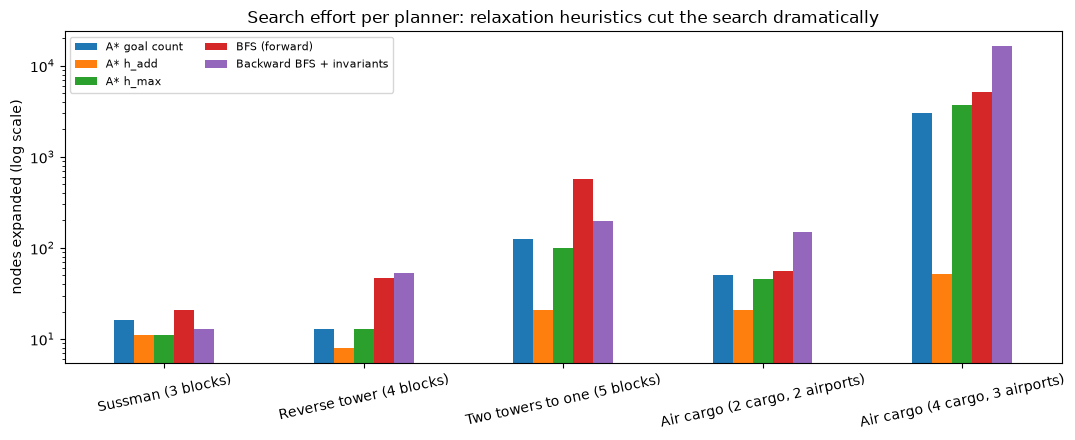

In [17]:
fig, ax = plt.subplots(figsize=(11, 4.5))
pivot = res.pivot(index="problem", columns="planner", values="nodes expanded").loc[list(problems)]
pivot.plot.bar(ax=ax, logy=True, rot=12)
ax.set_ylabel("nodes expanded (log scale)"); ax.set_xlabel("")
ax.set_title("Search effort per planner: relaxation heuristics cut the search dramatically")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

In [18]:
for pname in ["Sussman (3 blocks)", "Two towers to one (5 blocks)", "Air cargo (2 cargo, 2 airports)", "Air cargo (4 cargo, 3 airports)"]:
    plan = solved_plans[(pname, "A* h_max")]
    print(f"{pname}: optimal plan with {len(plan)} actions")
    for i, a in enumerate(plan, 1):
        print(f"   {i:2}. {a.name}")

Sussman (3 blocks): optimal plan with 6 actions
    1. unstack(c, a)
    2. put-down(c)
    3. pick-up(b)
    4. stack(b, c)
    5. pick-up(a)
    6. stack(a, b)
Two towers to one (5 blocks): optimal plan with 10 actions
    1. unstack(e, d)
    2. put-down(e)
    3. unstack(d, c)
    4. stack(d, e)
    5. pick-up(c)
    6. stack(c, d)
    7. unstack(b, a)
    8. stack(b, c)
    9. pick-up(a)
   10. stack(a, b)
Air cargo (2 cargo, 2 airports): optimal plan with 6 actions
    1. load(c1, p1, sfo)
    2. load(c2, p2, jfk)
    3. fly(p1, sfo, jfk)
    4. fly(p2, jfk, sfo)
    5. unload(c1, p1, jfk)
    6. unload(c2, p2, sfo)
Air cargo (4 cargo, 3 airports): optimal plan with 11 actions
    1. load(c1, p1, sfo)
    2. load(c2, p1, sfo)
    3. fly(p1, sfo, ord)
    4. load(c3, p2, jfk)
    5. load(c4, p1, ord)
    6. unload(c2, p1, ord)
    7. fly(p1, ord, jfk)
    8. fly(p2, jfk, sfo)
    9. unload(c1, p1, jfk)
   10. unload(c3, p2, sfo)
   11. unload(c4, p1, jfk)


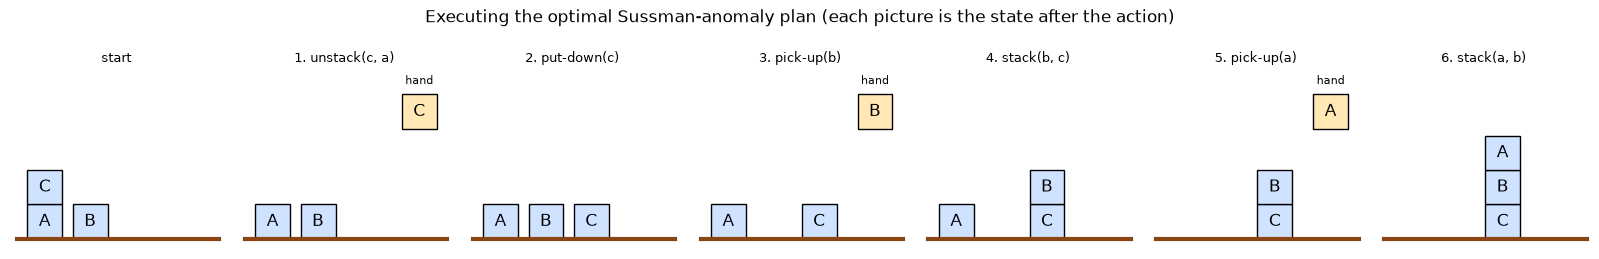

In [19]:
def draw_blocks(ax, state, title, objects=("a", "b", "c")):
    """Draw a blocks-world state: stacks on a table (one fixed slot per block), plus the held block."""
    on = {x[1]: x[2] for x in state if x[0] == "on"}
    bottoms = [x[1] for x in state if x[0] == "ontable"]
    for b in bottoms:
        i = objects.index(b)                          # a tower stands in the slot of its bottom block
        level, cur = 0, b
        while True:
            ax.add_patch(plt.Rectangle((i * 1.3, level), 1, 1, facecolor="#cfe2ff", edgecolor="black"))
            ax.text(i * 1.3 + 0.5, level + 0.5, cur.upper(), ha="center", va="center", fontsize=12)
            above = [t for t, u in on.items() if u == cur]
            if not above:
                break
            cur, level = above[0], level + 1
    held = [x[1] for x in state if x[0] == "holding"]
    if held:
        ax.add_patch(plt.Rectangle((4.2, 3.2), 1, 1, facecolor="#ffe8b3", edgecolor="black"))
        ax.text(4.7, 3.7, held[0].upper(), ha="center", va="center", fontsize=12)
        ax.text(4.7, 4.5, "hand", ha="center", fontsize=8)
    ax.plot([-0.3, 5.5], [0, 0], color="saddlebrown", lw=3)
    ax.set_xlim(-0.5, 5.6); ax.set_ylim(-0.3, 4.9); ax.axis("off"); ax.set_title(title, fontsize=9)

plan = solved_plans[("Sussman (3 blocks)", "A* h_max")]
states = simulate(sussman["init"], plan)
fig, axes = plt.subplots(1, len(states), figsize=(2.3 * len(states), 2.6))
for i, (ax, st) in enumerate(zip(axes, states)):
    draw_blocks(ax, st, "start" if i == 0 else f"{i}. {plan[i - 1].name}")
fig.suptitle("Executing the optimal Sussman-anomaly plan (each picture is the state after the action)")
plt.tight_layout(); plt.show()

**What just happened?**
- Every planner solved every problem, and every plan was **checked by simulation** (each action applicable, goal reached).
- BFS, A* with h_max and backward search all return **optimal** (shortest) plans; the asserts confirm A* with the admissible h_max matches BFS every time. The goal-count and h_add heuristics happened to find optimal plans here too, but they carry no guarantee.
- The **nodes expanded** table and bar chart show the payoff of heuristics: the more informed h_add expands far fewer nodes than BFS, especially on the larger problems. h_max is admissible but weak (it only looks at the single hardest goal) and is expensive to compute per node, so in the timing table it is often *slower* than plain BFS despite expanding fewer nodes.
- On air cargo the planners interleave the two planes' actions, and in the 4-cargo problem plane p1 collects c4 at ORD on its way to JFK, carrying two items at once. Nobody told the planner these tricks; they fall out of the search.
- Backward search was the *slowest* on the air-cargo problems: blind BFS has no heuristic, and our simple invariants still let many impossible goal sets through. Its advantage shows when a problem has many irrelevant objects and actions that forward search would wade through.

**Complexity.** The state space of the blocks world grows super-exponentially with the number of blocks, and deciding whether a STRIPS problem has a plan (PlanSAT) is **PSPACE-complete** in general (Bylander, 1994). Finding an *optimal* blocks-world plan is NP-hard, although finding *some* plan is easy (put everything on the table, then build the goal). Each A* expansion here costs O(|A|) to find applicable actions, plus the heuristic: h_max / h_add cost O(|A| · |facts|) per node in our simple fixed-point loop.

| Planner | Complete? | Optimal? | Notes |
|---|---|---|---|
| Forward BFS | yes | yes (unit costs) | explores everything near the start |
| Forward A* + h_max | yes | **yes** (admissible) | weak heuristic |
| Forward A* + h_add / FF-style | yes | no | the workhorse of modern satisficing planners (HSP, FF, Fast Downward) |
| Backward BFS | yes | yes | needs invariants to avoid impossible goal sets |

> 🎓 **Exam / interview tip:** "Why are relaxed-problem heuristics domain-independent?" Because they are computed from the PDDL action schemas alone: the same code gives a heuristic for blocks, cargo, or any new domain, with no human-designed estimate. This is why planning is often called "search with automatically derived heuristics".

## 12. The Sussman anomaly and partial-order planning

> **In plain English:** goals can get in each other's way, so a good planner interleaves the steps and only fixes the order when it must.

### Why goals interact

A naive planner might solve conjunctive goals **one at a time** and never undo an achieved goal (*linear planning* with goal protection, as in the original STRIPS). The **Sussman anomaly** (Gerald Sussman, 1975) defeats it: whichever goal you achieve first must be undone to achieve the other.

In [20]:
def achieve_one_at_a_time(init, goals_in_order, actions):
    """Linear planning: achieve each goal in turn with an optimal sub-plan, then check earlier goals."""
    state, plan, report = init, [], []
    achieved = set()
    for g in goals_in_order:
        sub, _ = bfs_plan(state, frozenset([g]), actions)          # shortest plan for this goal alone
        plan += sub
        state = simulate(state, sub)[-1]
        clobbered = [x for x in achieved if x not in state]        # did we destroy an earlier goal?
        achieved.add(g)
        report.append(f"achieve {g}: {[a.name for a in sub]}" + (f"  -> CLOBBERED {clobbered}" if clobbered else ""))
    return plan, state, report

for order in [[("on", "a", "b"), ("on", "b", "c")], [("on", "b", "c"), ("on", "a", "b")]]:
    plan, final, report = achieve_one_at_a_time(sussman["init"], order, sussman_actions)
    print("Goal order:", order); print("   " + "\n   ".join(report))
    print("   all goals hold at the end?", sussman["goal"] <= final, "\n")

Goal order: [('on', 'a', 'b'), ('on', 'b', 'c')]
   achieve ('on', 'a', 'b'): ['unstack(c, a)', 'put-down(c)', 'pick-up(a)', 'stack(a, b)']
   achieve ('on', 'b', 'c'): ['unstack(a, b)', 'put-down(a)', 'pick-up(b)', 'stack(b, c)']  -> CLOBBERED [('on', 'a', 'b')]
   all goals hold at the end? False 

Goal order: [('on', 'b', 'c'), ('on', 'a', 'b')]
   achieve ('on', 'b', 'c'): ['pick-up(b)', 'stack(b, c)']
   achieve ('on', 'a', 'b'): ['unstack(b, c)', 'put-down(b)', 'unstack(c, a)', 'put-down(c)', 'pick-up(a)', 'stack(a, b)']  -> CLOBBERED [('on', 'b', 'c')]
   all goals hold at the end? False 



**What just happened?** Achieving on(A, B) first (4 actions: clear C off A, then stack A on B) leaves the tower A-B with C on the table; but putting B on C then requires lifting A off B again, destroying the first goal. Achieving on(B, C) first (2 actions) builds the tower B-C-A with A buried at the bottom; getting A onto B then requires dismantling that tower, destroying on(B, C). Either way the subgoals **interact**. A planner must *interleave* the steps for the two goals, which is what the state-space planners above did automatically.

### Partial-order planning (POP), briefly

**Idea.** Instead of committing to a total order of actions, a **partial-order planner** keeps a plan as:
- a set of **steps** (actions), including a dummy *Start* (whose effects are the initial state) and *Finish* (whose preconditions are the goal);
- **ordering constraints** A ≺ B (A must happen before B);
- **causal links** A →ᵖ B ("A achieves p for B");
- a list of **open preconditions** to support.

It repeatedly picks an open precondition, adds a step (or reuses one) to achieve it, and resolves **threats**: a step C that deletes p and could fall between A →ᵖ B is ordered before A (**demotion**) or after B (**promotion**). This is the **principle of least commitment**: only order steps when you must. Any **linearization** (topological order) of the final partial plan is a valid total-order plan. POP planners (UCPOP, 1992) dominated in the 1990s; today state-space planners with heuristics are faster, but partial orders remain useful for flexible execution and multi-agent plans.

The classic example (AIMA): putting on socks and shoes.

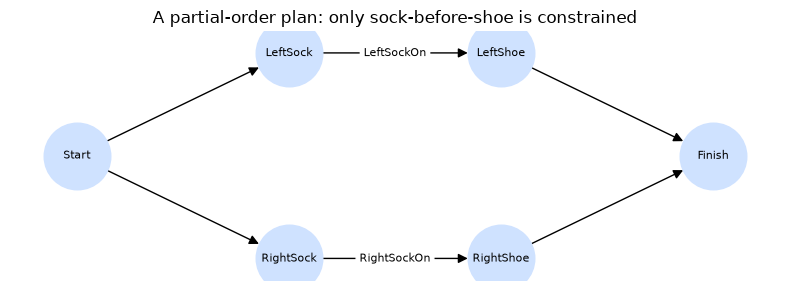

LeftSock → RightSock → LeftShoe → RightShoe   valid: True
LeftSock → RightSock → RightShoe → LeftShoe   valid: True
LeftSock → LeftShoe → RightSock → RightShoe   valid: True
RightSock → LeftSock → LeftShoe → RightShoe   valid: True
RightSock → LeftSock → RightShoe → LeftShoe   valid: True
RightSock → RightShoe → LeftSock → LeftShoe   valid: True

1 partial-order plan stands for 6 total-order plans, all valid.


In [21]:
pop_actions = {   # name: (preconditions, add list)
    "LeftSock":  (set(), {"LeftSockOn"}),
    "RightSock": (set(), {"RightSockOn"}),
    "LeftShoe":  ({"LeftSockOn"}, {"LeftShoeOn"}),
    "RightShoe": ({"RightSockOn"}, {"RightShoeOn"}),
}
causal_links = [("LeftSock", "LeftSockOn", "LeftShoe"), ("RightSock", "RightSockOn", "RightShoe")]
orderings = {(a, b) for a, p, b in causal_links}            # every causal link implies an ordering
goal_pop = {"LeftShoeOn", "RightShoeOn"}

g = nx.DiGraph()
g.add_nodes_from(["Start", "Finish", *pop_actions])
for a, p, b in causal_links:
    g.add_edge("Start", a)                         # Start precedes the socks ...
    g.add_edge(a, b, label=p)                      # ... a causal link sock -> shoe ...
    g.add_edge(b, "Finish")                        # ... and the shoes precede Finish
pos_pop = {"Start": (0, 0), "LeftSock": (1, 0.6), "RightSock": (1, -0.6), "LeftShoe": (2, 0.6), "RightShoe": (2, -0.6), "Finish": (3, 0)}
fig, ax = plt.subplots(figsize=(8, 3))
nx.draw_networkx(g, pos_pop, node_color="#cfe2ff", node_size=2300, font_size=8, arrowsize=14, ax=ax)
nx.draw_networkx_edge_labels(g, pos_pop, edge_labels=nx.get_edge_attributes(g, "label"), font_size=8, ax=ax)
ax.set_title("A partial-order plan: only sock-before-shoe is constrained"); ax.axis("off"); plt.tight_layout(); plt.show()

def linearizations(steps, orderings):
    return [p for p in itertools.permutations(steps)
            if all(p.index(a) < p.index(b) for a, b in orderings)]

def run_pop(order):
    state = set()
    for step in order:
        pre, add = pop_actions[step]
        if not pre <= state:
            return False
        state |= add
    return goal_pop <= state

lins = linearizations(list(pop_actions), orderings)
for p in lins:
    print(" → ".join(p), "  valid:", run_pop(p))
assert len(lins) == 6 and all(run_pop(p) for p in lins)
print(f"\n1 partial-order plan stands for {len(lins)} total-order plans, all valid.")

## 13. GraphPlan, briefly

> **In plain English:** GraphPlan draws a layered map of what could be true after 1, 2, 3... steps and uses it to find plans.

**GraphPlan** (Blum & Furst, 1997) builds a **planning graph**: alternating layers of facts (S₀, S₁, …) and actions (A₀, A₁, …). S₀ is the initial state; Aᵢ holds every action whose preconditions are in Sᵢ; Sᵢ₊₁ holds every fact in Sᵢ plus every effect of Aᵢ (so facts persist via "no-op" actions). The graph grows **polynomially**.

The key addition is **mutual exclusion (mutex)** links between pairs that cannot happen/hold together at that level:
- actions: **inconsistent effects** (one deletes what the other adds), **interference** (one deletes the other's precondition), **competing needs** (their preconditions are mutex);
- facts: **negation** (p and ¬p), **inconsistent support** (every way of achieving one is mutex with every way of achieving the other).

GraphPlan extends the graph until all goal facts appear **pairwise non-mutex**, then searches backwards through the graph for a plan, extending further if that fails. The level at which a goal first appears is an admissible heuristic; without mutexes it equals our h_max. Below we compute that **mutex-free** level for each Sussman goal and compare it with the true optimum.

In [22]:
def planning_graph_levels(init, actions, max_levels=10):
    """Fact layers of a planning graph WITHOUT mutexes (the delete relaxation)."""
    layers = [set(init)]
    for _ in range(max_levels):
        acts = [a for a in actions if a.pre <= layers[-1]]
        nxt = set(layers[-1]).union(*[a.add for a in acts])        # no-ops keep old facts
        if nxt == layers[-1]:
            break                                                  # the graph has levelled off
        layers.append(nxt)
    return layers

layers = planning_graph_levels(sussman["init"], sussman_actions)
rows = [{"level": i, "# facts": len(S), "new facts": show_atoms(S - (layers[i - 1] if i else set()))} for i, S in enumerate(layers)]
display(pd.DataFrame(rows))
first = {g: next(i for i, S in enumerate(layers) if g in S) for g in sussman["goal"]}
print("First level of each goal (no mutexes):", {f"on({g[1]}, {g[2]})": i for g, i in first.items()})
print("So the mutex-free graph suggests ≥", max(first.values()), "steps; the real optimum is", len(solved_plans[("Sussman (3 blocks)", "BFS (forward)")]))
assert max(first.values()) == h_max(sussman["init"], sussman["goal"], sussman_actions)

,level,# facts,new facts
0,0,6,"{clear(b), clear(c), handempty, on(c, a), ontable(a), ontable(b)}"
1,1,9,"{clear(a), holding(b), holding(c)}"
2,2,14,"{holding(a), on(b, a), on(b, c), on(c, b), ontable(c)}"
3,3,16,"{on(a, b), on(a, c)}"


First level of each goal (no mutexes): {'on(b, c)': 2, 'on(a, b)': 3}
So the mutex-free graph suggests ≥ 3 steps; the real optimum is 6


**What just happened?** Without mutexes both goal facts appear by level 3, because the relaxed graph lets the hand hold two blocks "at once" and never forces anything to be undone. Real GraphPlan marks pairs such as on(A, B) and on(B, C) as **mutex** at the early levels (they need incompatible histories), and keeps extending the graph and retrying its backward plan extraction until it succeeds. Here that happens at level 6: the single hand makes every pair of actions mutex (they all need or change `handempty`), so each level can hold only one real action. Mutex reasoning is what makes planning-graph heuristics stronger than plain h_max; GraphPlan's ideas also live on in SAT-based planners (SATPLAN), which encode a planning graph of fixed length as a SAT problem.

## 14. Hierarchical task networks (HTN), briefly

> **In plain English:** HTN planning breaks a big task ('get to the airport') into smaller recipes until only simple actions remain.

**Intuition.** People do not plan "go to the airport" as muscle twitches; they plan with abstract tasks ("get to the airport") and refine them ("take a taxi" → "call taxi, ride, pay").

**Definitions.** An **HTN planner** is given **tasks** to perform rather than a goal state.
- A **primitive task** is an ordinary action (with preconditions and effects).
- A **compound task** is decomposed by **methods**: each method says "under these conditions, task T can be done by subtasks T₁, …, Tₖ".
- The planner repeatedly replaces compound tasks by the subtasks of an applicable method until only primitive tasks remain. If it gets stuck it backtracks to another method.

HTN planning (e.g. SHOP2, Nau et al. 2003) is popular in industry and **game AI** because experts can encode "recipes" directly, and the hierarchy prunes the search enormously. In general it is more expressive than STRIPS (it can even be undecidable), so practical HTN planners restrict it (e.g. totally-ordered tasks, as below).

In [23]:
# State: where the traveller is, how much cash they have, where the taxi is.
distance = {("home", "park"): 1, ("home", "airport"): 25, ("home", "station"): 3, ("station", "airport"): 22}
dist = lambda a, b: distance.get((a, b)) or distance.get((b, a))

# Primitive operators: return the new state, or None if the precondition fails.
def walk(s, a, b):
    return {**s, "at": b} if s["at"] == a and dist(a, b) <= 3 else None
def call_taxi(s, a):
    return {**s, "taxi": a}
def ride_taxi(s, a, b):
    return {**s, "at": b, "taxi": b, "owe": 5 + 2 * dist(a, b)} if s["taxi"] == a and s["at"] == a else None
def pay_driver(s):
    return {**s, "cash": s["cash"] - s["owe"], "owe": 0} if s["cash"] >= s["owe"] else None
def ride_train(s, a, b):
    return {**s, "at": b, "cash": s["cash"] - 4} if s["at"] == a and s["cash"] >= 4 and {a, b} == {"station", "airport"} else None
operators = {"walk": walk, "call_taxi": call_taxi, "ride_taxi": ride_taxi, "pay_driver": pay_driver, "ride_train": ride_train}

# Methods for the compound task travel(a, b), tried in order.
def travel_on_foot(s, a, b):
    return [("walk", a, b)] if dist(a, b) <= 3 else None
def travel_by_taxi(s, a, b):
    return [("call_taxi", a), ("ride_taxi", a, b), ("pay_driver",)] if s["cash"] >= 5 + 2 * dist(a, b) else None
def travel_by_train(s, a, b):
    return [("travel", a, "station"), ("ride_train", "station", b)] if b == "airport" and a != "station" else None
methods = {"travel": [travel_on_foot, travel_by_taxi, travel_by_train]}

def htn_plan(state, tasks, depth=0, log=None):
    """Totally-ordered HTN planning (SHOP-style): decompose the first task, depth-first with backtracking."""
    if not tasks:
        return []
    task, rest = tasks[0], tasks[1:]
    name, args = task[0], task[1:]
    if name in operators:                                       # primitive: apply it
        new = operators[name](state, *args)
        if new is None:
            return None
        if log is not None: log.append("  " * depth + f"do {name}{args}")
        tail = htn_plan(new, rest, depth, log)
        return None if tail is None else [task] + tail
    for method in methods[name]:                                # compound: try each method
        subtasks = method(state, *args)
        if subtasks is None:
            continue
        if log is not None: log.append("  " * depth + f"{name}{args} via {method.__name__} -> {subtasks}")
        plan = htn_plan(state, subtasks + rest, depth + 1, log)
        if plan is not None:
            return plan
    return None

def execute(state, plan):
    for name, *args in plan:
        state = operators[name](state, *args)
        assert state is not None, f"{name} failed"               # validate the primitive plan by simulation
    return state

for cash, dest in [(20, "park"), (80, "airport"), (20, "airport")]:
    s0 = {"at": "home", "cash": cash, "taxi": "depot", "owe": 0}
    log = []
    plan = htn_plan(s0, [("travel", "home", dest)], log=log)
    final = execute(s0, plan)
    assert final["at"] == dest
    print(f"--- travel home -> {dest} with ${cash}:")
    print("\n".join(log))
    print(f"    primitive plan: {plan}\n    final state: {final}\n")

--- travel home -> park with $20:
travel('home', 'park') via travel_on_foot -> [('walk', 'home', 'park')]
  do walk('home', 'park')
    primitive plan: [('walk', 'home', 'park')]
    final state: {'at': 'park', 'cash': 20, 'taxi': 'depot', 'owe': 0}

--- travel home -> airport with $80:
travel('home', 'airport') via travel_by_taxi -> [('call_taxi', 'home'), ('ride_taxi', 'home', 'airport'), ('pay_driver',)]
  do call_taxi('home',)
  do ride_taxi('home', 'airport')
  do pay_driver()
    primitive plan: [('call_taxi', 'home'), ('ride_taxi', 'home', 'airport'), ('pay_driver',)]
    final state: {'at': 'airport', 'cash': 25, 'taxi': 'airport', 'owe': 0}

--- travel home -> airport with $20:
travel('home', 'airport') via travel_by_train -> [('travel', 'home', 'station'), ('ride_train', 'station', 'airport')]
  travel('home', 'station') via travel_on_foot -> [('walk', 'home', 'station')]
    do walk('home', 'station')
    do ride_train('station', 'airport')
    primitive plan: [('walk', 'hom

**What just happened?** With $20 and a short trip, the first method (walk) applied directly. For the airport with $80 the walk method was rejected (too far) and the taxi method was used. With only $20 the taxi (fare $55) was unaffordable, so the planner fell back to the third method: travel to the station (itself a compound task, solved on foot) and take the train. The planner never searched over raw actions; it only chose among expert-written recipes.

## 15. Planning vs search vs reinforcement learning

> **In plain English:** search finds paths, planning finds action sequences using a model of actions, and RL learns what to do by trial and error.

| | Uninformed / informed search | Classical planning | Reinforcement learning |
|---|---|---|---|
| Model of the world | a black-box successor function | **declarative, factored** action schemas (PDDL) | usually **none** (model-free) or learned |
| State representation | atomic (opaque) | **factored** (sets of facts) | atomic or feature vectors |
| Heuristics | hand-designed per problem | **derived automatically** from the schemas (relaxations) | learned value functions |
| Uncertainty | deterministic | deterministic (extensions: MDP/POMDP planning) | stochastic, by design |
| Output | a path | a plan (sequence or partial order) | a **policy** (what to do in every state) |
| Learns from experience? | no | no | **yes**, by trial and error with rewards |
| Typical use | route finding, puzzles | logistics, robotics task planning, space missions, game AI | games, control, recommender systems, LLM fine-tuning (RLHF) |

Planning sits between the two: like search it reasons with a model *before* acting; unlike plain search it exploits the **structure** of states and actions. RL is needed when there is no model or the world is too uncertain, at the price of lots of experience. Hybrids exist: **AlphaZero** combines learned value/policy networks with **Monte Carlo tree search** (planning) over a known model of the game.

## 16. Plan, execute, monitor, replan: the link to LLM agents

> **In plain English:** real plans meet surprises, so a good agent checks each step and replans when something has changed.

Classical planning assumes nothing unexpected happens. Real agents must **monitor execution**: before each action, check its preconditions in the *actual* state; if they fail (or the plan can no longer reach the goal), **replan** from the current state. This loop is called **execution monitoring and replanning** (AIMA §11.5).

Below, a mischievous child moves a block in the middle of execution.

In [24]:
def plan_and_execute(init, goal, actions, planner, disturbance=None):
    """Plan, then execute step by step; on a failed precondition, replan from the real state."""
    state, executed, log, disturbed = init, [], [], False
    plan = planner(state, goal, actions)
    log.append(f"PLAN ({len(plan)} steps): {[a.name for a in plan]}")
    step = 0
    while not goal <= state:
        if disturbance and step == disturbance[0] and not disturbed:
            state, disturbed = disturbance[1](state), True              # the world changes on its own (once)
            log.append(f"!! world changed: {disturbance[2]}")
        a = plan.pop(0) if plan else None
        if a is None or not applicable(state, a):                       # monitor: is the next step still possible?
            log.append(f"MONITOR: next action {a.name if a else '-'} not applicable -> REPLAN")
            plan = planner(state, goal, actions)
            log.append(f"PLAN ({len(plan)} steps): {[x.name for x in plan]}")
            continue
        state = result(state, a); executed.append(a); step += 1
        log.append(f"execute {a.name}")
    return executed, state, log

def child_puts_c_on_b(state):
    """Exogenous event: C is taken from wherever it is and put on top of B (if both are free)."""
    s = set(state) - {("ontable", "c"), ("clear", "b")} - {x for x in state if x[0] == "on" and x[1] == "c"}
    below = [x[2] for x in state if x[0] == "on" and x[1] == "c"]
    s |= {("on", "c", "b"), ("clear", "c")} | {("clear", u) for u in below}
    return frozenset(s)

planner = lambda s, g, acts: astar_plan(s, g, acts, h_add)[0]
executed, final, log = plan_and_execute(sussman["init"], sussman["goal"], sussman_actions, planner,
                                        disturbance=(2, child_puts_c_on_b, "a child puts C on top of B"))
print("\n".join(log))
assert sussman["goal"] <= final
print(f"\nGoal reached after executing {len(executed)} actions (the undisturbed plan needed 6).")

PLAN (6 steps): ['unstack(c, a)', 'put-down(c)', 'pick-up(b)', 'stack(b, c)', 'pick-up(a)', 'stack(a, b)']
execute unstack(c, a)
execute put-down(c)
!! world changed: a child puts C on top of B
MONITOR: next action pick-up(b) not applicable -> REPLAN
PLAN (6 steps): ['unstack(c, b)', 'put-down(c)', 'pick-up(b)', 'stack(b, c)', 'pick-up(a)', 'stack(a, b)']
execute unstack(c, b)
execute put-down(c)
execute pick-up(b)
execute stack(b, c)
execute pick-up(a)
execute stack(a, b)

Goal reached after executing 8 actions (the undisturbed plan needed 6).


**What just happened?** The agent planned the usual 6 steps and executed two of them (C was put down on the table). Then the world changed: C was placed on top of B. The monitor noticed that the next action (picking up B) was no longer applicable, so the agent **replanned from the real state** and still reached the goal, with a longer total plan.

**The same loop drives LLM agents.** A **plan-and-execute** agent (see [`10_Agents/02_memory_and_planning.ipynb`](../../10_Agents/02_memory_and_planning.ipynb)) asks a language model to write a list of steps (the **planner**), runs each step with tools (the **executor**), looks at the results (the **monitor**) and asks the model to revise the remaining steps when something fails (the **replanner**). The differences are instructive:

| | Classical planner | LLM plan-and-execute agent |
|---|---|---|
| Action model | exact PDDL preconditions and effects | implicit, in the model's weights and the tool descriptions |
| Plan validity | **guaranteed** by search and simulation | not guaranteed: plans can skip preconditions or hallucinate tools |
| Generality | only the domain you modelled | any task described in natural language |
| Replanning trigger | a precondition check fails | a tool error, an unexpected observation, or the model's own judgment |

Research has combined them: benchmarks such as **PlanBench** (Valmeekam et al., 2023) found that LLMs on their own often produce invalid blocks-world plans, while **LLM+P** (Liu et al., 2023) lets the LLM translate a request into PDDL and hands it to a classical planner, which returns a provably valid plan. Validating LLM plans with a simulator, exactly like our `is_valid_plan`, is a cheap and effective safeguard.

## 17. 🔗 How this connects to modern AI

| Classical idea | Where it lives today |
|---|---|
| Induction | all of machine learning: [`03_Machine_Learning`](../../03_Machine_Learning) learns rules from examples, with test sets guarding against bad generalisation |
| Abduction / diagnosis | Bayesian networks and probabilistic diagnosis (next notebook), root-cause analysis in monitoring systems, medical decision support |
| Analogical / case-based reasoning | retrieval-augmented generation (find the most similar past case and adapt it), few-shot prompting with worked examples |
| Common sense | large language models, which absorb much everyday knowledge from text but still need checking |
| Non-monotonic reasoning | closed-world databases and Prolog's negation as failure, belief updates in agents' memory, rule engines with priorities |
| STRIPS / PDDL planning | robot task planning (PDDL interfaces in robot software stacks), logistics and scheduling, space missions (NASA's Remote Agent flew an onboard planner on Deep Space 1 in 1999), game AI (goal-oriented action planning in F.E.A.R., 2005) |
| A* with relaxation heuristics | Fast Downward and other competition planners; the same idea (solve a relaxed problem to get a heuristic) is used across optimisation |
| HTN planning | game AI (several commercial games use HTN planners for non-player characters), workflow and manufacturing planning |
| Plan / execute / monitor / replan | **LLM agents** ([`10_Agents/02_memory_and_planning.ipynb`](../../10_Agents/02_memory_and_planning.ipynb)), robotics control loops, MCTS in AlphaZero-style systems; and RL for when there is no model ([`11_Reinforcement_Learning/01_rl_fundamentals.ipynb`](../../11_Reinforcement_Learning/01_rl_fundamentals.ipynb)) |

## 18. Recap

- **Deduction** is truth-preserving (modus ponens, modus tollens); **induction** generalises from examples and can be wrong (Find-S learned "Sunny ∧ Warm ∧ Strong wind"); **abduction** infers the best explanation and is defeasible (dead battery, then faulty starter when new evidence arrived).
- **Analogical** reasoning maps relational structure from a base to a target and transfers causally connected facts; **common-sense** reasoning needs huge amounts of unstated, default knowledge.
- Classical logic is **monotonic**; **non-monotonic** reasoning (defaults, specificity, negation as failure) lets new facts retract conclusions without making the KB inconsistent.
- **STRIPS/PDDL**: states are sets of facts, actions have preconditions, add and delete lists, RESULT(s, a) = (s − DEL) ∪ ADD, and everything else stays the same (closed world + STRIPS assumption).
- **Forward** planning searches states from the start; **backward** planning regresses goal sets through relevant actions. Automatically derived **relaxation heuristics** (ignore preconditions, ignore delete lists: h_max admissible, h_add informative) make A* fast.
- We solved Sussman, 4- and 5-block problems and two air-cargo problems; **every plan was validated by simulation**, and A* with h_max matched BFS's optimal lengths.
- **POP** keeps only necessary orderings (socks before shoes: 1 partial plan = 6 linear plans); **GraphPlan** adds mutexes to a layered graph; **HTN** decomposes tasks with expert methods.
- **Execution monitoring and replanning** closes the loop with the real world and is the classical ancestor of **plan-and-execute LLM agents**.

## Practice problems

**1. (Easy, conceptual)** Name the type of reasoning: (a) "Every swan I have seen is white, so all swans are white." (b) "The lawn is wet; it probably rained." (c) "All squares are rectangles; this is a square; so it is a rectangle." (d) "This new bug looks like last month's memory leak, so let's try the same fix."

<details><summary>Show solution</summary>

(a) inductive; (b) abductive (inference to the best explanation; a sprinkler is another explanation); (c) deductive; (d) analogical / case-based.
</details>

**2. (Easy)** Let S = {ontable(a), on(c, a), clear(c), holding(b)} (C sits on A, the hand holds B). Is `stack(b, c)` applicable? Which facts does it delete and add? Write RESULT(S, stack(b, c)) by hand, then check with code.

<details><summary>Show solution</summary>

Precondition {holding(b), clear(c)} ⊆ S, so it is applicable. Delete list: holding(b), clear(c). Add list: clear(b), handempty, on(b, c).
RESULT = (S − {holding(b), clear(c)}) ∪ {clear(b), handempty, on(b, c)} = **{ontable(a), on(c, a), on(b, c), clear(b), handempty}**.

```python
S = frozenset({("ontable", "a"), ("on", "c", "a"), ("clear", "c"), ("holding", "b")})
a = next(x for x in sussman_actions if x.name == "stack(b, c)")
print(applicable(S, a), show_atoms(result(S, a)))   # True {clear(b), handempty, on(b, c), on(c, a), ontable(a)}
```
</details>

**3. (Easy, conceptual)** Why is the goal-count heuristic not admissible in general? Give an action that would break it.

<details><summary>Show solution</summary>

Goal count assumes each action achieves at most one goal fact. If the goal were {ontable(a), clear(a)}, the single action `put-down(a)` achieves both, so the true cost is 1 while goal count says 2: an overestimate, so it is not admissible. With goals made only of `on` facts (as in our problems) each action adds at most one goal fact, and it is admissible.
</details>

**4. (Medium)** Regress the goal {on(a, b), on(b, c)} through `stack(a, b)`. Is `stack(b, c)` relevant to the original goal? Is `unstack(a, b)` relevant?

<details><summary>Show solution</summary>

REGRESS = (g − {on(a, b), clear(a), handempty}) ∪ {holding(a), clear(b)} = **{on(b, c), holding(a), clear(b)}**.
`stack(b, c)` adds on(b, c) and deletes holding(b), clear(c), neither in g, so it **is** relevant. `unstack(a, b)` deletes on(a, b), which is in g, so it is **not** relevant (it would destroy a goal).
</details>

**5. (Medium, coding)** Write a PDDL problem for 4 blocks where the initial state is the tower A on B on C on D and the goal is the same tower upside down **and** every block must end up clear except as required by stacking (just use the 3 `on` goals). Solve it with BFS and A* with h_add; compare nodes expanded, and verify the plans by simulation.

<details><summary>Show solution</summary>

This is our "Reverse tower" problem; here it is from scratch:
```python
txt = blocks_problem("rev", "abcd", "(on a b) (on b c) (on c d) (ontable d) (clear a) (handempty)",
                     "(on d c) (on c b) (on b a)")
p = parse_problem(txt); acts = ground(blocks_schemas, p["objects"], p["init"])
for name, run in [("BFS", lambda: bfs_plan(p["init"], p["goal"], acts)),
                  ("A* h_add", lambda: astar_plan(p["init"], p["goal"], acts, h_add))]:
    plan, expanded = run()
    assert is_valid_plan(p["init"], p["goal"], plan)
    print(name, len(plan), "steps,", expanded, "expanded")
```
Both find 8-step plans; A* with h_add expands far fewer nodes.
</details>

**6. (Medium, coding)** Extend the default-reasoning engine: add the class `"jetpack_penguin"` (a kind of penguin) whose default is that it flies. What does `flies({"bird", "penguin", "jetpack_penguin"})` return, and why?

<details><summary>Show solution</summary>

```python
strict_isa["jetpack_penguin"] = "penguin"
defaults["jetpack_penguin"] = True
print(flies({"bird", "penguin", "jetpack_penguin"}))   # (True, "default for 'jetpack_penguin'")
del strict_isa["jetpack_penguin"], defaults["jetpack_penguin"]   # clean up
```
`jetpack_penguin` is the most specific class (three is-a links above it), so its default beats the penguin default, which beat the bird default. Non-monotonicity in action: each new, more specific fact flips the conclusion.
</details>

**7. (Hard, coding)** Write an air cargo problem with 3 cargo items, 1 plane and 3 airports (SFO, JFK, ORD): c1 SFO→JFK, c2 JFK→ORD, c3 ORD→SFO, plane starting at SFO. Find an optimal plan length with A* + h_max and check it against BFS.

<details><summary>Show solution</summary>

```python
txt = """(define (problem cargo-3) (:domain air-cargo)
  (:objects c1 c2 c3 p1 sfo jfk ord)
  (:init (cargo c1) (cargo c2) (cargo c3) (plane p1) (airport sfo) (airport jfk) (airport ord)
         (at c1 sfo) (at c2 jfk) (at c3 ord) (at p1 sfo))
  (:goal (and (at c1 jfk) (at c2 ord) (at c3 sfo))))"""
p = parse_problem(txt); acts = ground(parse_domain(CARGO_DOMAIN), p["objects"], p["init"])
plan_a, _ = astar_plan(p["init"], p["goal"], acts, h_max)
plan_b, _ = bfs_plan(p["init"], p["goal"], acts)
assert is_valid_plan(p["init"], p["goal"], plan_a) and len(plan_a) == len(plan_b)
print(len(plan_a), [a.name for a in plan_a])   # 9 actions: a round trip SFO -> JFK -> ORD -> SFO
```
Each cargo needs a load and an unload (6 actions) and the plane must fly the triangle (3 flights): 9 actions.
</details>

## Further reading

- Russell & Norvig, *Artificial Intelligence: A Modern Approach*, 4th ed.: Ch. 10 (knowledge representation: categories, defaults, reasoning systems), Ch. 11 (Automated Planning).
- Ghallab, Nau & Traverso, *Automated Planning: Theory and Practice* (2004) and *Automated Planning and Acting* (2016).
- Mitchell, *Machine Learning* (1997), Ch. 2 (concept learning, Find-S). Brachman & Levesque, *Knowledge Representation and Reasoning* (2004), chapters on defaults.
- Free online: the *Planning.Wiki* PDDL reference (planning.wiki); the Fast Downward planner documentation (fast-downward.org).

## Next notebook

➡️ [`09_uncertain_knowledge_and_reasoning.ipynb`](09_uncertain_knowledge_and_reasoning.ipynb): reasoning under uncertainty with probability and Bayesian networks, the tool for the abductive diagnosis problems met in Section 4.

⬅️ Previous: [`07_knowledge_representation_and_logic.ipynb`](07_knowledge_representation_and_logic.ipynb)